# Trabajo Práctico: Calibración y Pose de la Cámara

**Universidad de Buenos Aires**  
Facultad de Ciencias Exactas y Naturales

**Materia:** Álgebra Lineal Computacional  
**Período:** Segundo cuatrimestre de 2026


## Grupo: tn-Milanesa_SVD

### Integrantes

| Nombre y apellido | LU |
| --- | --- |
| Rocco Gasparini | 102/24 |
| Benjamin Pondal | 551/24 |
| Ivan Schuster | 401/24 |
| Lautaro Hildt | 1166/24 |

## Resolución


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import alc
from alc import obtenerQ2d, estimarHomografia, armarA, calcularMatrizK2D, obtenerPose2D
import pandas as pd

### Ejercicio 1 - DLT ecuaciones formales

**a)** Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

**1. Rango de la matriz $Q$:**

La matriz $Q$ tiene dimensiones $2n \times 12$ y el vector $m$ pertenece a $\mathbb{R}^{12}$. Por el Teorema de la Dimensión, sabemos que:
$$ \dim(\mathbb{R}^{12}) = \text{Rango}(Q) + \dim(\text{Nu}(Q)) $$
$$ 12 = \text{Rango}(Q) + \dim(\text{Nu}(Q)) $$

Como el enunciado exige una solución no nula y única a menos de un factor de escala, la dimensión del núcleo de la matriz tiene que ser $1$. Despejando, obtenemos que el rango necesario de la matriz es:
$$ \text{Rango}(Q) = 11 $$

**2. Cantidad mínima de puntos:**

Cada correspondencia de puntos aporta exactamente 2 ecuaciones al sistema (dos filas a la matriz $Q$). Para alcanzar un rango de 11, necesitamos como mínimo 11 filas linealmente independientes.

* Con 6 correspondencias obtenemos 12 filas, por lo que es posible alcanzar el rango 11 requerido. Sin embargo, la cantidad de filas no garantiza que haya 11 linealmente independientes.

**3. Condiciones de los puntos:**
Para garantizar que el sistema alcance el rango 11, las coordenadas de los puntos elegidos no pueden ser arbitrarias.

* **Condición en el espacio 3D:**
Si todos los puntos de calibración pertenecen a un mismo plano, podemos elegir las coordenadas para que ese plano sea $W=0$. Entonces, las columnas de $Q$ correspondientes a $m_{13}$, $m_{23}$ y $m_{33}$ son nulas, por lo que estas tres incógnitas quedan libres.

Además, el sistema de los otros nueve coeficientes admite una solución no nula, correspondiente a la proyección del plano sobre la imagen. Por eso, esas nueve columnas son linealmente dependientes y tienen rango a lo sumo 8. Como las tres columnas nulas no aumentan el rango, resulta $\operatorname{Rango}(Q)\leq 8$.

Cada punto adicional fuera del plano aporta dos filas a $Q$, por lo que puede aumentar su rango como máximo en 2. Si agregamos un solo punto fuera del plano, obtenemos un rango a lo sumo 10. Por el teorema de la dimensión, el núcleo sigue teniendo dimensión al menos $12-10=2$: además de la libertad de escala, queda al menos otra libertad.

Por lo tanto, para alcanzar rango 11 partiendo de puntos de un mismo plano, necesitamos agregar al menos dos puntos fuera de él. Esto es necesario, pero no garantiza por sí solo alcanzar ese rango: las ecuaciones aportadas deben tener suficiente independencia.

* **Condición en el plano de la imagen:**
Si todos los puntos proyectados en la imagen estuvieran sobre una misma recta, podemos cambiar el sistema de referencia 2D mediante una rotación y una traslación para que esa recta coincida con el eje horizontal. En estas coordenadas, $v_i = 0$ para todos los puntos. Al reemplazar $v = 0$, la ecuación impar ($f_{2i+1}$) se reduce a:
$$ U \cdot m_{21} + V \cdot m_{22} + W \cdot m_{23} + 1 \cdot m_{24} = 0 $$

Geométricamente, esta es la ecuación de un plano en el espacio 3D. 
Si todos nuestros puntos 3D satisfacen esta ecuación, significa que viven sobre ese único plano. Sin embargo, por la condición anterior ya demostramos que el conjunto de puntos 3D no puede ser coplanar. 
Por lo tanto, la única forma de que un conjunto no coplanar de puntos satisfaga esa ecuación simultáneamente es que los coeficientes del plano sean nulos: **$m_{21} = m_{22} = m_{23} = m_{24} = 0$**. 

Al forzar a cero estas 4 variables, nos quedan 8 incógnitas por despejar ($m_1$ y $m_3$). Como las ecuaciones impares ya se consumieron forzando los ceros, solo nos quedan las filas pares (las de $u$). Utilizando el mínimo de 6 puntos, disponemos de apenas 6 ecuaciones útiles para resolver 8 incógnitas. 
Este sistema tiene un núcleo de dimensión al menos 2. Para que la solución sea única a menos de un factor de escala, esa dimensión debería ser 1. Por lo tanto, no se obtiene la unicidad buscada. El conteo anterior corresponde al caso de seis puntos. Para cualquier cantidad de puntos, podemos justificar esta condición observando que la submatriz formada por las primeras tres columnas de $M$ es proporcional a $KR$. Como $K$ y $R$ son invertibles, esa submatriz también debe serlo. Sin embargo, si $m_{21}=m_{22}=m_{23}=0$, tendría una fila nula y no sería invertible. Por lo tanto, los puntos de un conjunto 3D no coplanar no pueden proyectarse todos sobre una misma recta con una cámara de este modelo.

Las condiciones geométricas anteriores son necesarias, pero no garantizan por sí solas la unicidad. Además, las correspondencias elegidas deben producir una matriz $Q$ con 11 filas linealmente independientes, es decir, $\operatorname{Rango}(Q)=11$.


**b)** Encontrar el vector $m$ que resuelve la minimización de la ecuación $8$ del enunciado.

El objetivo es encontrar el vector $m$ que minimice la forma cuadrática $m^T Q^T Q m$, sujeto a la restricción $\|m\| = 1$. Para resolverlo, utilizamos la Descomposición en Valores Singulares (SVD) de la matriz $Q = U \Sigma V^T$. Reemplazando $Q$ en la función a minimizar, obtenemos $m^T V (\Sigma^T \Sigma) V^T m$.

Para simplificar la expresión, definimos el vector $y = V^T m$ y calculamos su norma al cuadrado para verificar cómo se ve afectada la restricción inicial:
$$ \|y\|^2 = y^T y = (V^T m)^T (V^T m) = m^T V V^T m $$

Dado que $V$ es una matriz ortogonal proveniente de la SVD, se cumple que $V V^T = I$. Por lo tanto:
$$ \|y\|^2 = m^T I m = m^T m = \|m\|^2 $$

Como la norma inicial requerida era $\|m\| = 1$, queda demostrado que la norma del nuevo vector $y$ también es estrictamente 1.

Sabiendo que $y = V^T m$ y $y^T = m^T V$, el problema se transforma en minimizar la expresión $y^T (\Sigma^T \Sigma) y$ sujeta a la restricción $\|y\|^2 = 1$. La matriz $\Sigma^T \Sigma$ es diagonal y contiene los valores singulares al cuadrado ordenados de mayor a menor ($\sigma_1^2 \ge \sigma_2^2 \ge \dots \ge \sigma_{12}^2 \ge 0$). Al desarrollar este producto matricial, obtenemos una sumatoria:
$$ y^T (\Sigma^T \Sigma) y = \sum_{i=1}^{12} \sigma_i^2 y_i^2 $$

Como los valores singulares están ordenados, cualquier $\sigma_i^2$ es mayor o igual al último valor $\sigma_{12}^2$. Esto nos permite armar la siguiente desigualdad para acotar la función por debajo:
$$ \sum_{i=1}^{12} \sigma_i^2 y_i^2 \ge \sum_{i=1}^{12} \sigma_{12}^2 y_i^2 $$

Sacando factor común el término constante en el lado derecho:
$$ \sum_{i=1}^{12} \sigma_i^2 y_i^2 \ge \sigma_{12}^2 \left( \sum_{i=1}^{12} y_i^2 \right) $$

Por la restricción comprobada anteriormente, sabemos que la sumatoria de los $y_i^2$ es exactamente igual a la norma al cuadrado de $y$, que es 1. Sustituyendo esto, llegamos a la cota:
$$ \sum_{i=1}^{12} \sigma_i^2 y_i^2 \ge \sigma_{12}^2 $$

Para que un valor sea efectivamente el mínimo de una función, basta con verificar que la función es siempre mayor o igual a ese valor, y además demostrar que existe al menos un vector que hace posible alcanzar exactamente ese valor. Para que nuestra sumatoria sea igual a $\sigma_{12}^2$, basta con proponer un vector $y$ que asigne todo el peso a la última variable y anule las demás:
$$ y = \begin{bmatrix} 0 \\ 0 \\ \vdots \\ 1 \end{bmatrix} $$

Este vector propuesto cumple con la restricción de norma unitaria y hace que la función tome el valor exacto $\sigma_{12}^2$, demostrando de forma rigurosa que dicho valor es el mínimo buscado.

Finalmente, a partir de la definición $y = V^T m$, multiplicamos a izquierda por $V$ de ambos lados para despejar la variable original:
$$ V y = V V^T m \implies m = V y $$

Al multiplicar la matriz $V$ por el vector $y$ propuesto, el resultado extrae la última columna de la matriz. En conclusión, el vector $m$ de norma unitaria que resuelve la minimización original corresponde a la última columna de la matriz ortogonal $V$, la cual se obtiene al aplicar la SVD sobre la matriz $Q$ del sistema DLT.

### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

Calcular un nuevo set de parámetros para 

b) $\alpha_u = \alpha_v$ 

c) $K_{12}=0$



#### Construcción de Q - ejercicio 2, inciso a del PDF

La función `obtenerQ3d` construye de forma directa la matriz $Q \in \mathbb{R}^{2n \times 12}$ del sistema homogéneo $Qm = 0$ a partir de las ecuaciones (5) y (6) del enunciado, donde $m \in \mathbb{R}^{12}$ contiene los coeficientes de la matriz de proyección $M \in \mathbb{R}^{3 \times 4}$ ordenados por filas.

Al despejar y eliminar el factor de escala homogéneo $\lambda$ en la proyección $\lambda [u, v, 1]^T = M [U, V, W, 1]^T$, cada correspondencia entre un punto 3D $(U, V, W)$ y su píxel $(u, v)$ aporta dos ecuaciones lineales independientes (una para $u$ y otra para $v$). En la implementación, inicializamos $Q$ con ceros de tamaño $2n \times 12$ y, tras validar las dimensiones de entrada, iteramos sobre los $n$ puntos ubicando en la fila par `2 * indice` la ecuación correspondiente a $u$ y en la fila impar `2 * indice + 1` la correspondiente a $v$:

$$Q_{2i} = [U, V, W, 1, 0, 0, 0, 0, -uU, -uV, -uW, -u]$$
$$Q_{2i+1} = [0, 0, 0, 0, U, V, W, 1, -vU, -vV, -vW, -v]$$

#### Resolución del sistema DLT - ejercicio 2, inciso b del PDF

Para encontrar la matriz de proyección $M$, el problema se reduce a encontrar el vector $m$ que minimiza $\|Qm\|^2$ sujeto a $\|m\|=1$, lo cual equivale a encontrar la última columna de la matriz $V$ proveniente de la Descomposición en Valores Singulares (SVD) de la matriz $Q$. 

Por definición de la SVD, las columnas de la matriz ortogonal $V$ corresponden exactamente a los autovectores de la matriz simétrica $Q^T Q$. Por lo tanto, en lugar de computar la SVD completa o lidiar con los recortes por tolerancia de la SVD reducida, resulta más directo calcular los autovectores de $Q^T Q$. 

Para ello, construimos $Q^TQ$ utilizando la multiplicación matricial del módulo y le aplicamos `diagRH`. Buscamos explícitamente el menor autovalor en la diagonal de la matriz devuelta y seleccionamos la columna de autovectores correspondiente. Normalizamos ese vector para que tenga norma 1 y lo reorganizamos en una matriz de $3 \times 4$ para obtener la matriz de proyección $M$.

#### Recuperación de R, t y K y restricciones opcionales - ejercicio 2, incisos c y d del PDF

Las ecuaciones (1) a (19) de este desarrollo tienen numeración propia. Las referencias a ecuaciones dentro de esta celda corresponden a esta numeración, no a la del enunciado.

La matriz $M$ que obtenemos como resultado en el inciso 2.b surge de resolver un sistema homogéneo donde forzamos que la norma del vector $m$ sea igual a 1. Debido a esta restricción, la matriz calculada difiere de la matriz teórica por un factor de escala no nulo $p$. 

Por lo tanto, la relación entre nuestra matriz práctica y los parámetros físicos del modelo se plantea matricialmente como $p M = K [R \mid t]$. Escribiendo las matrices completas con todos sus componentes, la igualdad es la siguiente:

$$ 
p \begin{bmatrix} 
m_{11} & m_{12} & m_{13} & m_{14} \\ 
m_{21} & m_{22} & m_{23} & m_{24} \\ 
m_{31} & m_{32} & m_{33} & m_{34} 
\end{bmatrix} 
= 
\begin{bmatrix} 
\alpha_u & \gamma & u_0 \\ 
0 & \alpha_v & v_0 \\ 
0 & 0 & 1 
\end{bmatrix} 
\begin{bmatrix} 
r_{11} & r_{12} & r_{13} & t_1 \\ 
r_{21} & r_{22} & r_{23} & t_2 \\ 
r_{31} & r_{32} & r_{33} & t_3 
\end{bmatrix} 
$$

Notamos que al fijar el elemento $K_{33} = 1$, garantizamos algebraicamente que el factor de escala homogéneo $\lambda$ en la proyección coincida con la coordenada de profundidad $Z$ del punto en el sistema de la cámara, permitiendo a su vez determinar de forma unívoca la magnitud del factor de escala $p$.

Para facilitar el cálculo analítico, agrupamos los componentes espaciales en vectores:
* Definimos $q_i$ como el vector formado por los tres primeros elementos de la fila $i$ de la matriz $M$ (es decir, $q_1 = [m_{11}, m_{12}, m_{13}]$, etc.). 
* Definimos $r_i$ como el vector correspondiente a la fila $i$ de la matriz de rotación $R$ ($r_1 = [r_{11}, r_{12}, r_{13}]$, etc.). 
* Los elementos de la última columna de $M$ los llamamos $m_{14}, m_{24}, m_{34}$, y los del vector de traslación son $t_1, t_2, t_3$.

Al desarrollar la multiplicación matricial fila por fila y separar la submatriz de rotación del vector de traslación, obtenemos el siguiente sistema de ecuaciones:

$$ p q_1 = \alpha_u r_1 + \gamma r_2 + u_0 r_3 \tag{1} $$
$$ p q_2 = \alpha_v r_2 + v_0 r_3 \tag{2} $$
$$ p q_3 = r_3 \tag{3} $$
$$ p m_{14} = \alpha_u t_1 + \gamma t_2 + u_0 t_3 \tag{4} $$
$$ p m_{24} = \alpha_v t_2 + v_0 t_3 \tag{5} $$
$$ p m_{34} = t_3 \tag{6} $$

A su vez, por definición del modelo, sabemos que $R$ debe ser una matriz ortogonal ($R R^T = I$). Esto aporta un segundo bloque de ecuaciones fundamentales sobre sus filas: el producto interno entre dos filas distintas es cero, y la norma 2 de cada fila es igual a 1:

$$ r_1 \cdot r_2 = 0 \tag{7} $$
$$ r_1 \cdot r_3 = 0 \tag{8} $$
$$ r_2 \cdot r_3 = 0 \tag{9} $$
$$ \|r_1\|_2 = 1 \tag{10} $$
$$ \|r_2\|_2 = 1 \tag{11} $$
$$ \|r_3\|_2 = 1 \tag{12} $$

Con todas las ecuaciones planteadas, el proceso de despeje se realiza fila por fila:

1. **Tercera fila y magnitud de escala:**
   Tomamos la ecuación (3) y aplicamos la norma 2 a ambos lados. Por la ecuación (12), sabemos que $\|r_3\|_2 = 1$, por lo que obtenemos $\|p q_3\|_2 = |p| \|q_3\|_2 = 1$. Inicialmente tomamos el valor positivo del factor de escala:

   $$ p = \frac{1}{\|q_3\|_2} \tag{13} $$

   Con $p$ definido, la ecuación (3) nos da directamente el vector unitario $r_3 = p q_3$.

2. **Segunda fila ($v_0$, $\alpha_v$ y $r_2$):**
   Tomamos la ecuación (2) y realizamos el producto interno con $r_3$ a ambos lados: $p (q_2 \cdot r_3) = \alpha_v (r_2 \cdot r_3) + v_0 (r_3 \cdot r_3)$. Por las ecuaciones (9) y (12), se anula el término con $\alpha_v$ y despejamos $v_0$:

   $$ v_0 = p (q_2 \cdot r_3) \tag{14} $$

   Aislando el término de $\alpha_v$ en la ecuación (2), tenemos $\alpha_v r_2 = p q_2 - v_0 r_3$. Como $r_3=pq_3$, el lado derecho es $p(q_2-v_0q_3)$. La independencia lineal de $q_2$ y $q_3$, junto con $p\neq0$, asegura que este vector no sea nulo. Por lo tanto, su norma es positiva:

   $$ \alpha_v = \|p q_2 - v_0 r_3\|_2 > 0 \tag{15} $$

   Dividiendo por $\alpha_v$, obtenemos el vector unitario $r_2 = \frac{p q_2 - v_0 r_3}{\alpha_v}$.

3. **Primera fila ($u_0$, $\gamma$, $\alpha_u$ y $r_1$):**
   Aplicamos el producto interno con $r_3$ a ambos lados de la ecuación (1). Por las ecuaciones (8), (9) y (12), desaparecen los términos de $\alpha_u$ y $\gamma$, despejando $u_0$:

   $$ u_0 = p (q_1 \cdot r_3) \tag{16} $$

   Aplicamos ahora el producto interno con $r_2$ en la ecuación (1). Por las ecuaciones (7), (9) y (11), se anulan los términos de $\alpha_u$ y $u_0$, despejando el sesgo (skew) $\gamma$:

   $$ \gamma = p (q_1 \cdot r_2) \tag{17} $$

   De la ecuación (1), obtenemos $\alpha_u r_1 = p q_1 - \gamma r_2 - u_0 r_3$. Al expresar $r_2$ y $r_3$ en función de $q_2$ y $q_3$, queda una combinación lineal de $q_1,q_2,q_3$ cuyo coeficiente de $q_1$ es $p\neq0$. Por independencia lineal, el vector no es nulo y su norma es positiva:

   $$ \alpha_u = \|p q_1 - \gamma r_2 - u_0 r_3\|_2 > 0 \tag{18} $$

   Dividiendo este vector resultante por $\alpha_u$, obtenemos el primer vector unitario $r_1 = \frac{p q_1 - \gamma r_2 - u_0 r_3}{\alpha_u}$.

4. **Condición de rotación propia ($\det(R) = +1$) y signo de $p$:**
   Por construcción, $RR^T=I$ y, por lo tanto, $\det(R)=\pm1$. Para que $R$ sea una rotación propia, exigimos $\det(R)=1$.

   Como $M$ está definida salvo escala, podemos elegir el signo de $p=\pm1/\|q_3\|_2$. Si con $p>0$ obtenemos $\det(R)=-1$, cambiamos simultáneamente $p\leftarrow-p$ y $R\leftarrow-R$. Al ser $R$ de tamaño $3\times3$, resulta $\det(-R)=-\det(R)=1$.

   Este cambio conserva los parámetros de $K$ y, en particular, las focales positivas.

5. **Restricciones opcionales sobre $K$ (Inciso 2d), recálculo de $R$ y despeje de $t$:**
   Si se imponen las restricciones opcionales, modificamos los parámetros intrínsecos de $K$:
   * Si se solicita ausencia de sesgo (`fuerza_k12_0 = True`), se fija $\gamma = 0$.
   * Si se solicita igualdad de escalas focales (`fuerza_au_av_iguales = True`), se adopta el valor promedio para ambos ejes: $\alpha_u = \alpha_v = \frac{\alpha_{u,\text{real}} + \alpha_{v,\text{real}}}{2}$.

   Al modificar $K$ frente a datos con ruido, la factorización original deja de cumplirse exactamente. Para recalcular $R$ conservando su ortogonalidad, primero despejamos la matriz $C = K^{-1} (p M[:, :3])$, cuyas filas ya no son estrictamente ortonormales. Luego, calculamos su SVD ($C = U \Sigma V^T$) y reemplazamos $\Sigma$ por la identidad para obtener la matriz ortogonal más cercana: $R = U V^T$. Como el signo de $p$ ya fue corregido y $\det(K) = \alpha_u \alpha_v > 0$, se cumple que $\det(C) > 0$, por lo que el producto $R = U V^T$ conserva $R R^T = I$ y $\det(R) = 1$.

   Finalmente, con el signo definitivo de $p$ y los parámetros finales de $K$, despejamos de abajo hacia arriba las componentes del vector de traslación $t = [t_1, t_2, t_3]^T$ a partir de las ecuaciones (6), (5) y (4):

   $$ t_3 = p m_{34}, \qquad t_2 = \frac{p m_{24} - v_0 t_3}{\alpha_v}, \qquad t_1 = \frac{p m_{14} - \gamma t_2 - u_0 t_3}{\alpha_u} \tag{19} $$

#### Verificación práctica de `obtenerQ3d` y `resolverDLT3D` - ejercicio 2, incisos a y b del PDF

Para comprobar el funcionamiento de las funciones implementadas utilizamos los datos de `calib/3d`:
- `p_W_corners.txt`: contiene las 12 filas con las coordenadas $(U, V, W)$ de los 12 puntos 3D de la mira de calibración.
- `detected_corners.txt`: cada fila contiene los 24 valores $u_1, v_1, u_2, v_2, \dots, u_{12}, v_{12}$ detectados en cada captura. En particular, la primera fila (índice 0) corresponde a `img_0001.jpg` y la fila 50 (índice 49) corresponde a `img_0050.jpg`.

Usamos los seis puntos de índices pares para construir $Q\in\mathbb{R}^{12\times12}$ y estimar $M\in\mathbb{R}^{3\times4}$. Los puntos elegidos pertenecen a las tres caras de la mira y no son todos coplanares.

Los otros seis puntos, de índices impares, no intervienen en la estimación. Los reproyectamos con $M$ y comparamos sus píxeles estimados con los provistos por la cátedra, mediante el error medio en píxeles y su superposición sobre `img_0001.jpg`.

Dimensiones de Q (con 6 puntos): (12, 12)
Matriz de proyección M estimada con 6 puntos:
 [[ 0.0652  0.0228 -0.0126  0.8375]
 [ 0.0044  0.0609  0.0146  0.5382]
 [ 0.0001  0.0000  0.0001  0.0051]]
Distancia media entre píxeles reales y reproyectados (6 puntos de prueba): 1.3406 px


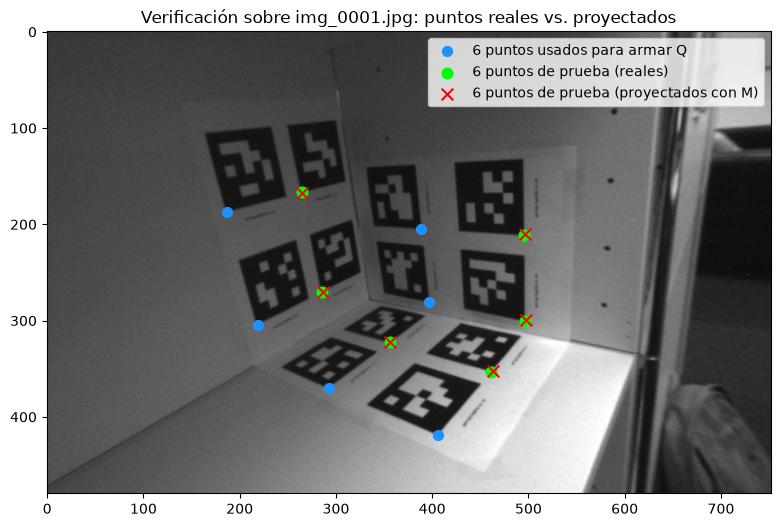

In [2]:

np.set_printoptions(precision=4, suppress=True, floatmode='fixed')

# Localizamos la carpeta de calibración 3D

carpeta_3d = ' calib/3d'

# Cargamos los 12 puntos 3D del mundo y las esquinas detectadas en las imágenes
obj_pts_3d = np.loadtxt(os.path.join(carpeta_3d, 'p_W_corners.txt'), delimiter=',')
det_corners = np.loadtxt(os.path.join(carpeta_3d, 'detected_corners.txt'))

# Extraemos las coordenadas (u, v) de la fila 0 (correspondiente a img_0001.jpg)
fila_img1 = det_corners[0]
u_img1 = fila_img1[0::2]
v_img1 = fila_img1[1::2]
img_pts_1 = np.vstack((u_img1, v_img1)).T

# Separamos intercaladamente (uno y uno): 6 puntos para armar Q y 6 puntos para probar
obj_train = obj_pts_3d[0::2]
img_train = img_pts_1[0::2]

obj_test = obj_pts_3d[1::2]
img_test = img_pts_1[1::2]

# Inciso 2a y 2b: construimos Q con los 6 puntos de entrenamiento y calculamos M
Q_6 = alc.obtenerQ3d(img_train, obj_train)
M_6 = alc.resolverDLT3D(Q_6)

print('Dimensiones de Q (con 6 puntos):', Q_6.shape)
print('Matriz de proyección M estimada con 6 puntos:\n', M_6)

# Proyectamos los otros 6 puntos 3D usando M_6 para comparar con los píxeles reales
cantidad_test = obj_test.shape[0]
u_est = np.zeros(cantidad_test)
v_est = np.zeros(cantidad_test)

for i in range(cantidad_test):
    U, V, W = obj_test[i]
    punto_3d_hom = np.array([[U], [V], [W], [1.0]])
    proy_hom = alc.mult_mat(M_6, punto_3d_hom)
    u_est[i] = proy_hom[0, 0] / proy_hom[2, 0]
    v_est[i] = proy_hom[1, 0] / proy_hom[2, 0]

errores_px = np.sqrt((img_test[:, 0] - u_est)**2 + (img_test[:, 1] - v_est)**2)
print(f'Distancia media entre píxeles reales y reproyectados (6 puntos de prueba): {np.mean(errores_px):.4f} px')

# Graficamos sobre img_0001.jpg los puntos reales de prueba y los estimados con M_6
img_1 = mpimg.imread(os.path.join(carpeta_3d, 'img_0001.jpg'))

plt.figure(figsize=(10, 6))
plt.imshow(img_1)
plt.scatter(img_train[:, 0], img_train[:, 1], color='dodgerblue', s=50, label='6 puntos usados para armar Q')
plt.scatter(img_test[:, 0], img_test[:, 1], color='lime', s=60, label='6 puntos de prueba (reales)')
plt.scatter(u_est, v_est, color='red', marker='x', s=70, label='6 puntos de prueba (proyectados con M)')
plt.title('Verificación sobre img_0001.jpg: puntos reales vs. proyectados')
plt.legend()
plt.show()

#### Verificación de `devolverMatricesCalibracion3d` - ejercicio 2, incisos c y d del PDF

A continuación, descomponemos la matriz de proyección $M$ mediante `devolverMatricesCalibracion3d` para obtener las matrices $R$, $t$ y $K$, verificando que $K$ sea triangular superior con $K_{33} = 1$ y que $R$ sea ortonormal ($R R^T = I$). Luego volvemos a calcular e imprimir los parámetros imponiendo las restricciones $\alpha_u = \alpha_v$ y $K_{12} = 0$.

Las distancias focales y las coordenadas del centro principal de $K$ se expresan en píxeles. La matriz $R$ no tiene unidades y describe la orientación del sistema del objeto respecto de la cámara. El vector $t$ conserva las unidades de las coordenadas de `p_W_corners.txt` y representa la posición del origen del objeto en el sistema de la cámara, según $p_{\mathrm{cámara}}=Rp_{\mathrm{objeto}}+t$.


In [3]:
# Calculamos Q y M usando los 12 puntos de img_0001.jpg
Q_12 = alc.obtenerQ3d(img_pts_1, obj_pts_3d)
M_12 = alc.resolverDLT3D(Q_12)

# Inciso 2c: Descomposición sin restricciones adicionales
R, t, K = alc.devolverMatricesCalibracion3d(M_12)

print('=== Calibración sin restricciones (Inciso 2c) ===')
print('Matriz M:\n', M_12)
print('Matriz K (triangular superior):\n', K)
print('Matriz de rotación R:\n', R)
print('Verificación de ortonormalidad R * R^T:\n', alc.mult_mat(R, R.T))
print('Vector de traslación t:', t)

=== Calibración sin restricciones (Inciso 2c) ===
Matriz M:
 [[ 0.0645  0.0228 -0.0140  0.8378]
 [ 0.0037  0.0610  0.0131  0.5378]
 [ 0.0001  0.0000  0.0001  0.0051]]
Matriz K (triangular superior):
 [[425.8599  -0.0156 354.4185]
 [  0.0000 424.5653 256.8534]
 [  0.0000   0.0000   1.0000]]
Matriz de rotación R:
 [[ 0.6182  0.1292 -0.7753]
 [-0.3551  0.9259 -0.1288]
 [ 0.7012  0.3549  0.6183]]
Verificación de ortonormalidad R * R^T:
 [[ 1.0000 -0.0000  0.0000]
 [-0.0000  1.0000  0.0000]
 [ 0.0000  0.0000  1.0000]]
Vector de traslación t: [-18.1679 -14.5033  40.5913]


In [4]:
# Inciso 2d - Caso 1: Imponiendo au = av
R_au_av, t_au_av, K_au_av = alc.devolverMatricesCalibracion3d(M_12, fuerza_au_av_iguales=True)
print('=== Restricción au = av ===')
print('Matriz K:\n', K_au_av)
print('Vector t:', t_au_av)

# Inciso 2d - Caso 2: Imponiendo K12 = 0
R_k12, t_k12, K_k12 = alc.devolverMatricesCalibracion3d(M_12, fuerza_k12_0=True)
print('=== Restricción K12 = 0 ===')
print('Matriz K:\n', K_k12)
print('Vector t:', t_k12)

# Inciso 2d - Caso 3: Imponiendo au = av y K12 = 0 simultáneamente
R_ambas, t_ambas, K_ambas = alc.devolverMatricesCalibracion3d(M_12, fuerza_k12_0=True, fuerza_au_av_iguales=True)
print('=== Restricciones au = av y K12 = 0 ===')
print('Matriz K:\n', K_ambas)
print('Vector t:', t_ambas)

=== Restricción au = av ===
Matriz K:
 [[425.2126  -0.0156 354.4185]
 [  0.0000 425.2126 256.8534]
 [  0.0000   0.0000   1.0000]]
Vector t: [-18.1956 -14.4812  40.5913]
=== Restricción K12 = 0 ===
Matriz K:
 [[425.8599   0.0000 354.4185]
 [  0.0000 424.5653 256.8534]
 [  0.0000   0.0000   1.0000]]
Vector t: [-18.1674 -14.5033  40.5913]
=== Restricciones au = av y K12 = 0 ===
Matriz K:
 [[425.2126   0.0000 354.4185]
 [  0.0000 425.2126 256.8534]
 [  0.0000   0.0000   1.0000]]
Vector t: [-18.1951 -14.4812  40.5913]


Sin restricciones, las distancias focales estimadas son aproximadamente $425{,}86$ y $424{,}57$ píxeles, cercanas entre sí, y el sesgo $K_{12}$ es de $-0{,}0156$ píxeles, próximo a cero.

Al imponer $\alpha_u=\alpha_v$, ambas focales se fijan en su promedio, aproximadamente $425{,}21$ píxeles. Al imponer $K_{12}=0$, se anula el sesgo. En ambos casos los cambios respecto de los parámetros iniciales son pequeños.

Al imponer las restricciones, la implementación recalcula la rotación $R$ mediante la SVD de $C=K^{-1}(pM[:, :3])$, tomando $R=UV^T$. La traslación $t$ se calcula utilizando los parámetros finales de $K$.

### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


#### Ítem 1 - Condición sobre el rango de $Q$

¿Qué rango debe tener $Q\in\mathbb{R}^{2n\times9}$ para asegurar una solución única de $H$ a menos de un factor de escala?

La matriz $Q\in\mathbb{R}^{2n\times 9}$ debe tener rango 8 para asegurar una solución única de $H$ a menos de un factor de escala.

El vector $h$ contiene los nueve elementos de la matriz $H$ y pertenece a $\mathbb{R}^{9}$. El conjunto de soluciones de la ecuación $Qh=0$ es el núcleo de $Q$. El vector $h=0$ siempre es solución. Sin embargo, produciría $H=0$, que no representa una homografía válida. Por eso buscamos una solución no nula.

Por otro lado, buscamos una solución única de $H$ a menos de un factor de escala. Esto quiere decir que, si $H_1$ y $H_2$ son dos soluciones no nulas, entonces $H_1=cH_2$ para algún escalar $c\neq0$. Multiplicar $H$ por un escalar no nulo no cambia las coordenadas de la imagen, porque ese factor se cancela al dividir por la tercera coordenada homogénea. Para que todas las soluciones no nulas sean múltiplos entre sí, el espacio de soluciones debe tener dimensión uno o, lo que es lo mismo, $\dim(\operatorname{Nu} Q)=1$.

Como $Q$ tiene nueve columnas, representa una transformación lineal con dominio $\mathbb{R}^{9}$. Por el teorema de la dimensión,

$$
\dim(\operatorname{Im} Q)+\dim(\operatorname{Nu} Q)=9.
$$

Recordemos que $\dim(\operatorname{Im} Q)=\operatorname{Rango}(Q)$ y acabamos de ver que $\dim(\operatorname{Nu} Q)=1$. Luego,

$$
\operatorname{Rango}(Q)+1=9,
$$

por lo tanto, $\operatorname{Rango}(Q)=8$.


#### Ítem 2 - Construcción de $Q$

`obtenerQ2d(imgPts, objPts)` recibe las correspondencias entre puntos del tablero $(U_i,V_i)$ y de la imagen $(u_i,v_i)$, en el mismo orden. Cada correspondencia aporta las dos ecuaciones indicadas en la ecuación 11 del enunciado. Al apilarlas se obtiene $Q\in\mathbb{R}^{2n\times9}$ para el sistema $Qh=0$, donde $h$ contiene las entradas de $H$ ordenadas por filas.

Para obtener las homografías que se usan en el ítem siguiente, normalizamos los puntos según la sección 2.3 del enunciado, construimos $Q$ con esos puntos normalizados y elegimos el autovector del menor autovalor de $Q^TQ$, pidiendo que $\|h\|_2=1$. Por último, desnormalizamos $H$ para que vuelva a relacionar las coordenadas originales del tablero y de la imagen: $H=T_{\mathrm{img}}^{-1}\check H T_{\mathrm{obj}}$.


#### Ítem 3 - Construcción de $A$

*Aclaración: $r_1, r_2 \in \mathbb{R}^{3 \times 1}$ son la primera y la segunda columna de $R$, respectivamente. En el ejercicio 2, $r_i$ representaba la fila $i$ de $R$.*

`armarA(Hlst)` recibe una lista de homografías, cada una obtenida de una imagen distinta. Como la matriz de rotación es ortogonal entonces, en particular, las dos primeras columnas de la rotación son ortogonales entre si, y ambas tienen norma 1. Esto nos provee de dos restricciones por homografía: $c_1^TBc_2=0$ y $c_1^TBc_1-c_2^TBc_2=0$, con $B=K^{-T}K^{-1}$ y $c_1,c_2$ columnas de $H$.

Apilamos sus coeficientes como filas $v_{12}^T$ y $(v_{11}-v_{22})^T$, en el orden de incógnitas $b=(B_{11},B_{12},B_{22},B_{13},B_{23},B_{33})^T$. Así, obtenemos $Ab=0$, con $A\in\mathbb{R}^{2N\times6}$ para $N$ homografías.


#### Ítem 4 - Cálculo de la matriz intrínseca $K$

`calcularMatrizK2D(A)` obtiene $b$ como un autovector unitario del menor autovalor de $A^TA$, resolviendo $\min_{\|b\|_2=1}\|Ab\|_2^2$. Reconstruye la matriz simétrica $B=K^{-T}K^{-1}$ con el orden de incógnitas del ítem 3. Como el signo de $b$ es arbitrario, prueba $B$ y $-B$ y utiliza el que admite la factorización de Cholesky $B=LL^T$.

De esa relación se recupera $K=(L^T)^{-1}$ y se normaliza dividiendo por $K_{33}$. Así, $K$ es triangular superior, sus distancias focales son positivas y $K_{33}=1$. Si ninguno de los signos permite Cholesky, la función devuelve `None`.


#### Ítem 5 - Recuperación de la pose

Para una homografía $H=[c_1\ c_2\ c_3]$, la relación $H=sK[r_1\ r_2\ t]$ permite obtener columnas proporcionales a $r_1$, $r_2$ y $t$ mediante $K^{-1}H$. Se recupera la escala con $|\lambda|=1/\|K^{-1}c_1\|_2$ y se elige su signo para que el origen del tablero quede delante de la cámara.

`obtenerPose2D(Hj, K)` aplica esa escala, ortonormaliza las primeras dos columnas mediante Gram-Schmidt y construye $r_3=r_1\times r_2$. Así obtiene una rotación con $R^TR=I$ y $\det(R)=1$ y devuelve $(R,t)$ con la convención $p_{\mathrm{cámara}}=Rp_{\mathrm{tablero}}+t$.

Observar que la traslación tiene las unidades del tablero, no es directamente la posición de la cámara en el mundo.


#### Datos y correspondencias

El tablero tiene 77 esquinas internas, con coordenadas $(U,V)=(30i,30j)$ mm, donde $i=0,\ldots,10$ y $j=0,\ldots,6$. Para la calibración seleccionamos ocho esquinas bien repartidas: las cuatro extremas, los puntos medios de los bordes superior e inferior y los puntos medios de los laterales. Sus índices son $(0,0)$, $(5,0)$, $(10,0)$, $(0,3)$, $(10,3)$, $(0,6)$, $(5,6)$ y $(10,6)$.

Elegimos como origen la esquina interna superior izquierda del tablero en cada imagen. Ordenamos las correspondencias primero por fila y luego por columna. Ocho puntos aportan 16 ecuaciones para estimar cada homografía, por encima del mínimo de cuatro correspondencias en posición general.

**Material disponible:** Veinte imágenes, desde `Im_R_1.png` hasta `Im_R_20.png`.


#### Coordenadas de las esquinas

El archivo `coordenadas_coplanar_manual.csv` reúne las correspondencias de las veinte imágenes: ocho esquinas internas por imagen y 160 puntos en total, con columnas `imagen,i,j,u,v`. Los índices `i,j` identifican la esquina del tablero y permiten obtener sus coordenadas métricas como U=30i y V=30j, en milímetros. Las coordenadas `u,v` se expresan en píxeles de la fotografía original, con origen en su esquina superior izquierda.

Las posiciones se obtuvieron por lectura visual de las fotografías originales ampliadas, y se registraron en píxeles enteros.

Ordenamos las filas de cada imagen primero por `j` y luego por `i`, y construimos tanto los puntos del tablero como los de imagen a partir de esas mismas filas. Mostramos las coordenadas del CSV sobre las imágenes 1, 10 y 20 para observar las correspondencias utilizadas y el origen elegido.


In [5]:

datos = np.loadtxt('coordenadas_coplanar_manual.csv', delimiter=',', skiprows=1, dtype=str)
mediciones = {}
for nombre, i, j, u, v in datos:
    if nombre not in mediciones:
        mediciones[nombre] = []
    mediciones[nombre].append((int(i), int(j), float(u), float(v)))

archivos = sorted(mediciones, key=lambda nombre: int(nombre.split('_')[-1].split('.')[0]))
puntos_objeto = {}
puntos_imagen = {}
for nombre in archivos:
    registros = sorted(mediciones[nombre], key=lambda punto: (punto[1], punto[0]))
    puntos_objeto[nombre] = np.array([[30 * punto[0], 30 * punto[1]] for punto in registros], dtype=float)
    puntos_imagen[nombre] = np.array([[punto[2], punto[3]] for punto in registros])

print('Imágenes con correspondencias:', len(archivos))
print('Correspondencias por imagen:', puntos_imagen[archivos[0]].shape[0])
print('Total de puntos del CSV:', datos.shape[0])
print('Coordenadas del tablero en mm | coordenadas de imagen en píxeles.')


Imágenes con correspondencias: 20
Correspondencias por imagen: 8
Total de puntos del CSV: 160
Coordenadas del tablero en mm | coordenadas de imagen en píxeles.


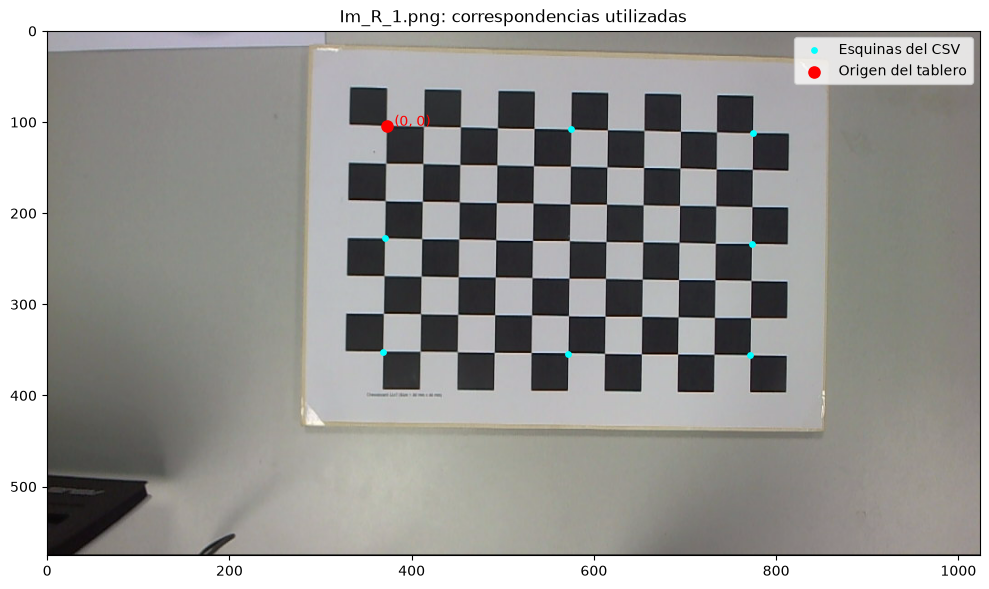

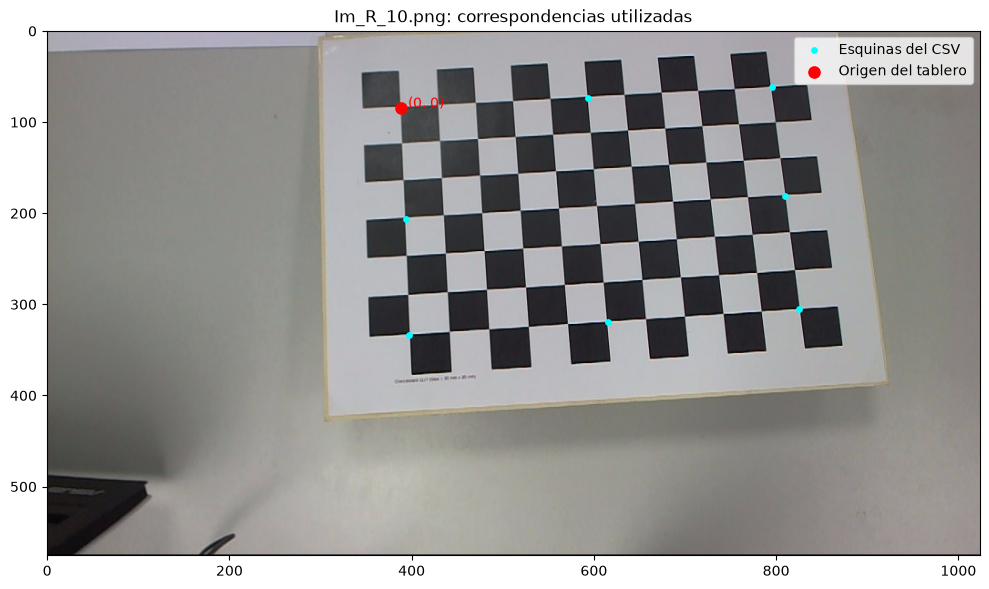

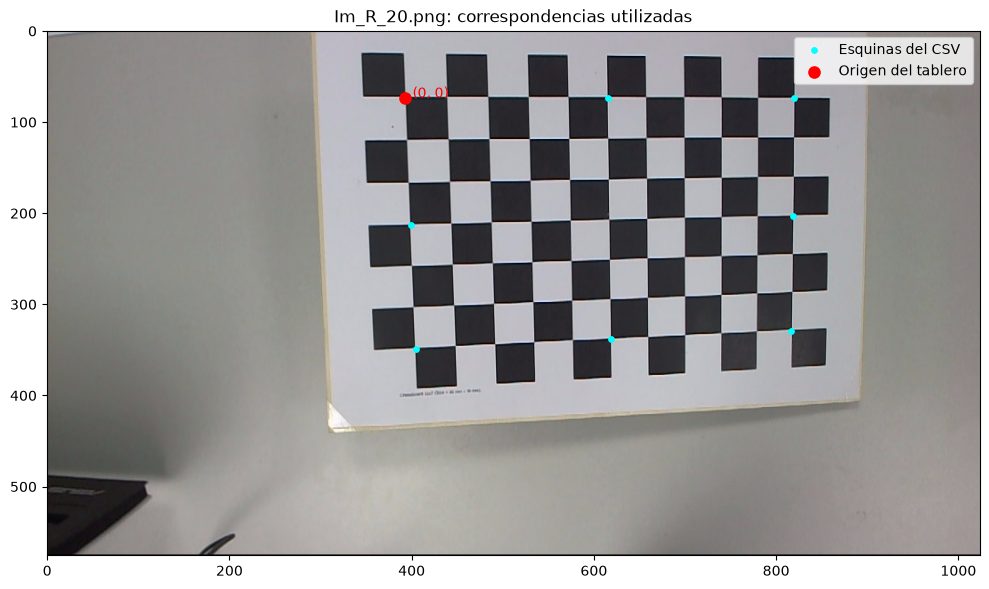

In [6]:

for nombre in ['Im_R_1.png', 'Im_R_10.png', 'Im_R_20.png']:
    imagen = mpimg.imread(os.path.join(' calib', 'coplanar', nombre))
    puntos = puntos_imagen[nombre]
    plt.figure(figsize=(10, 6))
    plt.imshow(imagen)
    plt.scatter(puntos[:, 0], puntos[:, 1], s=15, color='cyan', label='Esquinas del CSV')
    plt.scatter(puntos[0, 0], puntos[0, 1], s=65, color='red', label='Origen del tablero')
    plt.text(puntos[0, 0] + 8, puntos[0, 1], '(0, 0)', color='red')
    plt.title(nombre + ': correspondencias utilizadas')
    plt.legend()
    plt.tight_layout()
    plt.show()


#### Homografías de las imágenes

Con las correspondencias anteriores calculamos una homografía por imagen mediante `estimarHomografia`, que realiza la normalización, el DLT y la desnormalización explicados en el ítem 2. Cada homografía relaciona las coordenadas del tablero en milímetros con los píxeles de su imagen.


In [7]:
homografias = {}
for nombre in archivos:
    homografias[nombre] = estimarHomografia(puntos_imagen[nombre], puntos_objeto[nombre])

Hlst = [homografias[nombre] for nombre in archivos]
print('Homografías calculadas:', len(Hlst))
primera_imagen = archivos[0]
Q = obtenerQ2d(puntos_imagen[primera_imagen], puntos_objeto[primera_imagen])
print('Dimensiones de Q por imagen:', Q.shape)


Homografías calculadas: 20
Dimensiones de Q por imagen: (16, 9)


#### a) Obtener la matriz $\mathbf{K}$

Cada homografía aporta dos restricciones. Construimos $A$ con `armarA` y recuperamos una única matriz intrínseca $K$, común a todas las imágenes, mediante `calcularMatrizK2D`.


In [8]:
A = armarA(Hlst)
K = calcularMatrizK2D(A)
if K is None:
    raise ValueError('Las homografías no produjeron una matriz B definida positiva.')

print('Dimensiones de A:', A.shape)
print('K =')
print(K)
print(f'Distancias focales (píxeles): {K[0, 0]:.4f}, {K[1, 1]:.4f}')
print(f'Centro principal (píxeles): {K[0, 2]:.4f}, {K[1, 2]:.4f}')
print(f'Sesgo (píxeles): {K[0, 1]:.4f}')


Dimensiones de A: (40, 6)
K =
[[745.2763  -1.7901 511.1841]
 [  0.0000 756.9873 310.9821]
 [  0.0000   0.0000   1.0000]]
Distancias focales (píxeles): 745.2763, 756.9873
Centro principal (píxeles): 511.1841, 310.9821
Sesgo (píxeles): -1.7901


La diagonal de $K$ contiene las dos distancias focales en píxeles y el valor de normalización $K_{33}=1$. Las dos primeras entradas de la tercera columna indican las coordenadas del centro principal, también en píxeles. El sesgo $K_{12}$, que en Python corresponde a `K[0,1]`, se expresa en píxeles. Estimamos estos parámetros sin imponer distancias focales iguales ni sesgo nulo.


#### b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$

Usamos la misma K y la homografía correspondiente a cada imagen. Mostramos R y t para las tres imágenes solicitadas.


In [9]:
poses = {}
for nombre in ['Im_R_1.png', 'Im_R_10.png', 'Im_R_20.png']:
    R, t = obtenerPose2D(homografias[nombre], K)
    poses[nombre] = (R, t)
    print(nombre)
    print('R =')
    print(R)
    print('t (mm) =', t)
    print()


Im_R_1.png
R =
[[ 0.9995 -0.0123 -0.0289]
 [ 0.0124  0.9999  0.0023]
 [ 0.0289 -0.0026  0.9996]]
t (mm) = [-102.4904 -150.6966  550.4834]

Im_R_10.png
R =
[[ 0.9971  0.0707 -0.0273]
 [-0.0658  0.9865  0.1501]
 [ 0.0375 -0.1479  0.9883]]
t (mm) = [ -89.6245 -161.9256  540.1856]

Im_R_20.png
R =
[[ 0.9893  0.0271 -0.1432]
 [-0.0416  0.9942 -0.0991]
 [ 0.1397  0.1040  0.9847]]
t (mm) = [ -77.7630 -153.6169  487.9954]



Las poses se expresan respecto del sistema de coordenadas del tablero elegido en cada imagen: R describe su orientación respecto de la cámara y t ubica su origen en coordenadas de cámara, en milímetros. La calibración utiliza las correspondencias de las veinte imágenes provistas, leídas desde el CSV. 




### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de radio alrededor de los jugadores argentinos.

Primero vamos a calcular la homografía $H$, y para eso necesitamos 4 puntos de referencia. La matriz $H$ la necesitamos para pasar de puntos del plano de la cancha $(U, V)$ a puntos en la imagen $(u, v)$, mientras que su inversa $H^{-1}$ nos permite pasar de puntos de la imagen $(u, v)$ a puntos de la cancha $(U, V)$.

**Plan de resolución:**
1. **Estimar $H$ y $H^{-1}$:** Tomamos 4 puntos de referencia del campo cuyas coordenadas reales $(U, V)$ en metros conocemos por el archivo `futbol/estadio_azteca.png` y buscamos sus coordenadas en píxeles $(u, v)$ dentro de la foto. Con esos 4 puntos vamos a calcular $H$ y luego la vamos a invertir para obtener $H^{-1}$.
2. **Calcular la distancia de Enzo al arco:** Ubicamos el píxel de los pies de Enzo en la imagen y le aplicamos $H^{-1}$ para obtener su posición $(U_{\text{Enzo}}, V_{\text{Enzo}})$ en metros sobre el césped. Con ello calculamos tanto la distancia perpendicular a la línea del arco ($x = 105\text{ m}$) como la distancia al centro del arco.
3. **Dibujar los círculos alrededor de los jugadores argentinos:** Identificamos los píxeles de los pies de cada jugador argentino y los transformamos con $H^{-1}$ para hallar la posición de cada uno en metros sobre la cancha. Luego construimos en coordenadas de la cancha los puntos del contorno de un círculo centrado en cada jugador y proyectamos todos esos puntos de vuelta a la foto multiplicando por $H$ para graficarlos sobre la imagen.

Vamos a tomar los siguientes puntos:

- P1: vértice del área chica que según `futbol/estadio_azteca.png` tiene coordenada $y = (\text{ancho\_cancha}/2) + (18.32/2) = 34 + 9.16 = 43.16$ y $x = \text{largo\_cancha} - 5.5 = 105 - 5.5 = 99.5$. Por lo tanto $P_1 = [99.5, 43.16]$.

- P2: palo del arco que según `futbol/estadio_azteca.png` tiene coordenada $y = (\text{ancho\_cancha}/2) - (\text{ancho\_arco}/2) = (68/2) - (7.32/2) = 34 - 3.66 = 30.34$ y $x = \text{largo\_cancha} = 105$. Por lo tanto $P_2 = [105, 30.34]$.

- P3: otro vértice del área chica que según `futbol/estadio_azteca.png` tiene coordenada $y = (\text{ancho\_cancha}/2) - (18.32/2) = 34 - 9.16 = 24.84$ y $x = \text{largo\_cancha} - 5.5 = 105 - 5.5 = 99.5$. Por lo tanto $P_3 = [99.5, 24.84]$.

- P4: el punto de penal que según `futbol/estadio_azteca.png` tiene coordenada $y = \text{ancho\_cancha}/2 = 68/2 = 34$ y $x = \text{largo\_cancha} - 11 = 105 - 11 = 94$. Por lo tanto $P_4 = [94, 34]$.

Buscamos qué píxel tiene cada punto en la imagen, sumando como $P_5$ la posición de los pies de Enzo:

$P_1 = (156, 232)$
$P_2 = (653, 184)$
$P_3 = (868, 252)$
$P_4 = (511, 318)$
$P_5 = (809, 541)$

A continuación graficamos los puntos para corroborar que estén bien ubicados. Luego calculamos $H$ y usamos $H^{-1}$ para obtener las coordenadas de Enzo en el campo y calcular tanto la distancia perpendicular a la línea de fondo ($x = 105$) como la distancia euclídea hasta el centro del arco en $(105, 34)$.

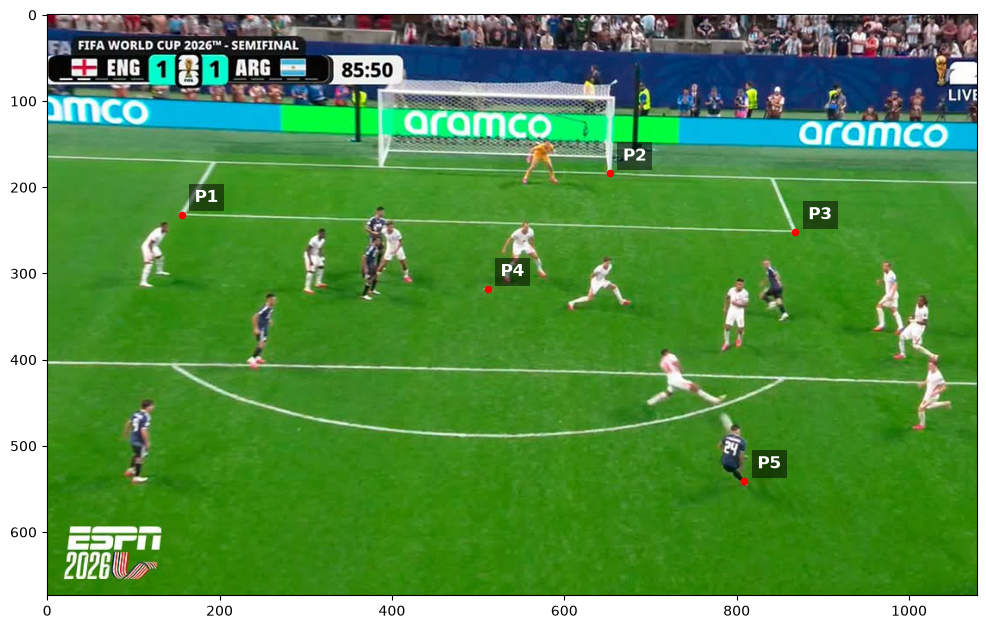

In [10]:

img = mpimg.imread('futbol/test-gol-enzo.png')
puntos = [(156, 232), (653, 184), (868, 252), (511, 318), (809, 541)]

plt.figure(figsize=(12, 8))
plt.imshow(img)

for i, punto in enumerate(puntos):
    # Dibuja el punto rojo usando scatter (permitido)
    plt.scatter(punto[0], punto[1], color='red', s=20)
    plt.text(punto[0] + 15, punto[1] - 15, f'P{i+1}', 
             color='white', fontsize=12, fontweight='bold', 
             bbox=dict(facecolor='black', alpha=0.5, edgecolor='none'))

plt.show()

In [11]:

obj_pts = np.array([
    [99.5, 43.16],
    [105.0, 30.34],
    [99.5, 24.84],
    [94.0, 34.0]
], dtype=np.float32)

img_pts = np.array([
    [156, 232], 
    [653, 184],  
    [868, 252],
    [511, 318]  
], dtype=np.float32)

H = alc.estimarHomografia(img_pts, obj_pts)
H_inv = alc.inversa(H)                   

u_enzo, v_enzo = 809, 541 

pie_enzo_img = np.array([[u_enzo], [v_enzo], [1]])
enzo_cancha_homogeneo = alc.mult_mat(H_inv, pie_enzo_img)        

U_enzo = enzo_cancha_homogeneo[0, 0] / enzo_cancha_homogeneo[2, 0]
V_enzo = enzo_cancha_homogeneo[1, 0] / enzo_cancha_homogeneo[2, 0]

distancia_linea_fondo = 105.0 - U_enzo
distancia_centro_arco = np.sqrt((105.0 - U_enzo)**2 + (34.0 - V_enzo)**2)

print(f"Posición de Enzo en la cancha: X = {U_enzo:.4f} m, Y = {V_enzo:.4f} m")
print(f"Distancia perpendicular a la línea de fondo: {distancia_linea_fondo:.4f} m")
print(f"Distancia al centro del arco: {distancia_centro_arco:.4f} m")

Posición de Enzo en la cancha: X = 82.8676 m, Y = 28.1488 m
Distancia perpendicular a la línea de fondo: 22.1324 m
Distancia al centro del arco: 22.8928 m


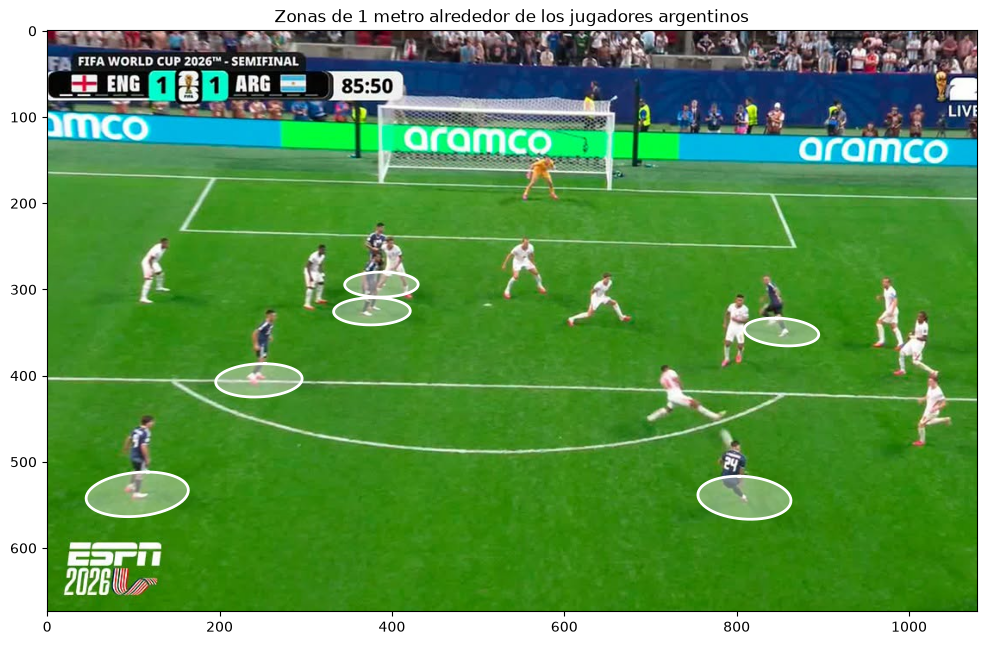

In [12]:

# Píxeles donde están ubicados los pies de los jugadores argentinos
jugadores_argentinos_img = [
    (246, 405),
    (105, 537),
    (377, 325),
    (388, 294),
    (852, 349),
    (809, 541)
]

# Generamos un círculo base de radio 1 metro usando trigonometría
angulos = np.arange(0, 2 * np.pi + 0.1, 0.1)
x_loop = np.cos(angulos)
y_loop = np.sin(angulos)
cantidad_puntos_circulo = len(x_loop)

# Preparamos la figura con la imagen de fondo
plt.figure(figsize=(12, 8))
plt.imshow(mpimg.imread('futbol/test-gol-enzo.png'))

# Iteramos sobre cada jugador para proyectar su zona
for u_jug, v_jug in jugadores_argentinos_img:
    
    # Pasamos las coordenadas del jugador en la foto al plano de la cancha
    pie_img = np.array([[u_jug], [v_jug], [1.0]])
    pie_cancha_homogeneo = alc.mult_mat(H_inv, pie_img)
    
    # Normalizamos dividiendo por el factor de escala de la tercera componente
    U_jug = pie_cancha_homogeneo[0, 0] / pie_cancha_homogeneo[2, 0]
    V_jug = pie_cancha_homogeneo[1, 0] / pie_cancha_homogeneo[2, 0]
    
    # Trasladamos el círculo base para que se centre en los pies del jugador
    U_circulo = U_jug + x_loop
    V_circulo = V_jug + y_loop
    
    # Preparamos los arrays para ir guardando las proyecciones a la imagen
    u_proyectado = np.zeros(cantidad_puntos_circulo)
    v_proyectado = np.zeros(cantidad_puntos_circulo)
    
    # Proyectamos cada punto del contorno de la cancha de vuelta a la foto
    for k in range(cantidad_puntos_circulo):
        punto_cancha = np.array([[U_circulo[k]], [V_circulo[k]], [1.0]])
        punto_img_homogeneo = alc.mult_mat(H, punto_cancha)
        
        # Guardamos la coordenada normalizada calculando su píxel correspondiente
        u_proyectado[k] = punto_img_homogeneo[0, 0] / punto_img_homogeneo[2, 0]
        v_proyectado[k] = punto_img_homogeneo[1, 0] / punto_img_homogeneo[2, 0]
        
    # Dibujamos el relleno semitransparente interior y el contorno exterior
    plt.fill(u_proyectado, v_proyectado, color='white', alpha=0.4)
    plt.plot(u_proyectado, v_proyectado, color='white', linewidth=2)

plt.title("Zonas de 1 metro alrededor de los jugadores argentinos")
plt.show()

b) Calcular la homografía de la cancha de fútbol de la foto $\texttt{posibleoffside.jpg}$. 
    Trazar sobre la fotografía una recta sobre el pie del jugador del equipo defensor que defina si hay fuera de juego.
    

Para resolver el inciso b) sobre la imagen `posibleoffside.jpg`, primero debemos estimar su propia matriz de homografía $H$. Para ello tomamos 5 puntos de referencia del campo de juego cuyas coordenadas reales conocemos a partir de `futbol/estadio_azteca.png` (considerando el largo de la cancha de $105\text{ m}$ y el ancho de $68\text{ m}$):

- **P1 (Punto del penal):** ubicado en el centro del ancho de la cancha y a $11\text{ m}$ de la línea de fondo: $y = \text{ancho\_cancha}/2 = 68/2 = 34$ y $x = \text{largo\_cancha} - 11 = 105 - 11 = 94$. Por lo tanto, $P_1 = [94.0, 34.0]$.

- **P2 (Vértice derecho del área grande mirando al arco de frente):** sabiendo que el área grande mide $40.32\text{ m}$ de ancho y $16.5\text{ m}$ de profundidad, sus coordenadas son $y = (\text{ancho\_cancha}/2) - (40.32/2) = 34 - 20.16 = 13.84$ y $x = \text{largo\_cancha} - 16.5 = 105 - 16.5 = 88.5$. Por lo tanto, $P_2 = [88.5, 13.84]$.

- **P3 (Vértice izquierdo del área grande mirando al arco de frente):** simétrico al anterior respecto al centro: $y = (\text{ancho\_cancha}/2) + (40.32/2) = 34 + 20.16 = 54.16$ y $x = \text{largo\_cancha} - 16.5 = 105 - 16.5 = 88.5$. Por lo tanto, $P_3 = [88.5, 54.16]$.

- **P4 (Vértice derecho del área chica mirando al arco de frente):** sabiendo que el área chica mide $18.32\text{ m}$ de ancho y $5.5\text{ m}$ de profundidad, tiene coordenada $y = (\text{ancho\_cancha}/2) - (18.32/2) = 34 - 9.16 = 24.84$ y $x = \text{largo\_cancha} - 5.5 = 105 - 5.5 = 99.5$. Por lo tanto, $P_4 = [99.5, 24.84]$.

- **P5 (Vértice izquierdo del área chica mirando al arco de frente):** simétrico al anterior respecto al centro: $y = (\text{ancho\_cancha}/2) + (18.32/2) = 34 + 9.16 = 43.16$ y $x = \text{largo\_cancha} - 5.5 = 105 - 5.5 = 99.5$. Por lo tanto, $P_5 = [99.5, 43.16]$.

Identificamos los píxeles correspondientes a cada punto en la imagen, agregando como $P_6$ la posición del pie del último defensor:

$P_1 = (1010, 475)$
$P_2 = (732, 758)$
$P_3 = (735, 316)$
$P_4 = (1363, 578)$
$P_5 = (1228, 390)$
$P_6 = (824, 330)$

A continuación graficamos los puntos sobre la imagen para verificar que estén bien ubicados. Luego calculamos la homografía $H$ y su inversa $H^{-1}$, llevamos la posición del pie del defensor ($P_6$) al plano de la cancha para obtener su coordenada longitudinal $U_{\text{def}}$, y finalmente definimos una recta paralela a la línea de fondo (con $U = U_{\text{def}}$ constante y $V$ variando a lo ancho del campo) que proyectamos nuevamente a la imagen mediante $H$.

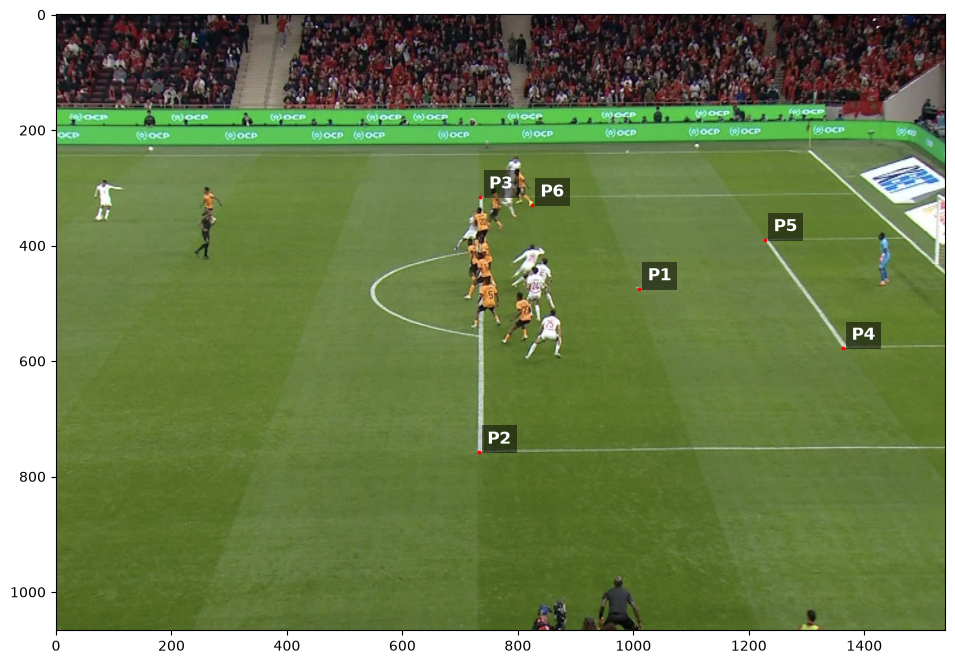

In [13]:

img_offside = mpimg.imread('futbol/test-fuera-de-juego.png')
puntos_offside = [(1010, 475), (732, 758), (735, 316), (1363, 578), (1228, 390), (824, 330)]

plt.figure(figsize=(12, 8))
plt.imshow(img_offside)

for i, punto in enumerate(puntos_offside):
    plt.scatter(punto[0], punto[1], color='red', s=3)
    plt.text(punto[0] + 15, punto[1] - 15, f'P{i+1}', 
             color='white', fontsize=12, fontweight='bold', 
             bbox=dict(facecolor='black', alpha=0.5, edgecolor='none'))

plt.show()

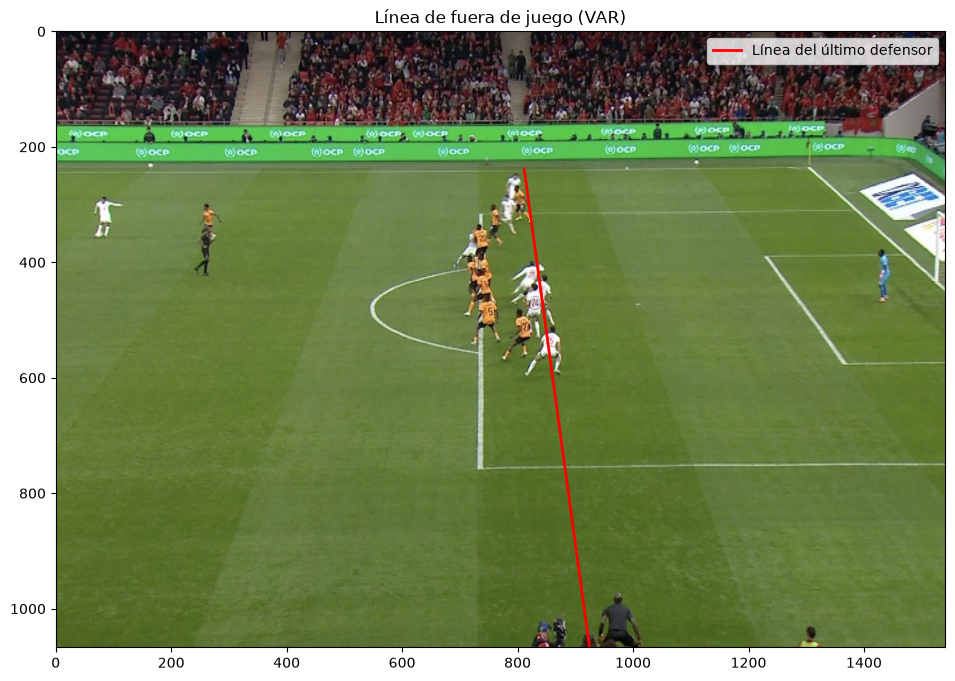

In [14]:

# Puntos de control en coordenadas de la cancha
obj_pts_off = np.array([
    [94.0, 34.0],
    [88.5, 13.84],
    [88.5, 54.16],
    [99.5, 24.84],
    [99.5, 43.16]
], dtype=np.float32)

# Píxeles correspondientes en la imagen
img_pts_off = np.array([
    [1010, 475],
    [732, 758],
    [735, 316],
    [1363, 578],
    [1228, 390]
], dtype=np.float32)

# Calculamos la homografía y su inversa
H_off = alc.estimarHomografia(img_pts_off, obj_pts_off)
H_off_inv = alc.inversa(H_off)

# Llevamos el pie del último defensor al plano de la cancha
u_def, v_def = 824, 330
pie_def_img = np.array([[u_def], [v_def], [1.0]])
def_cancha_homogeneo = alc.mult_mat(H_off_inv, pie_def_img)

U_def = def_cancha_homogeneo[0, 0] / def_cancha_homogeneo[2, 0]
V_def = def_cancha_homogeneo[1, 0] / def_cancha_homogeneo[2, 0]

# Definimos la recta de lado a lado de la cancha (V de 0 a 68 metros)
extremo_1_cancha = np.array([[U_def], [0.0], [1.0]])
extremo_2_cancha = np.array([[U_def], [68.0], [1.0]])

# Proyectamos ambos extremos a la imagen
extremo_1_img_hom = alc.mult_mat(H_off, extremo_1_cancha)
extremo_2_img_hom = alc.mult_mat(H_off, extremo_2_cancha)

u_1 = extremo_1_img_hom[0, 0] / extremo_1_img_hom[2, 0]
v_1 = extremo_1_img_hom[1, 0] / extremo_1_img_hom[2, 0]

u_2 = extremo_2_img_hom[0, 0] / extremo_2_img_hom[2, 0]
v_2 = extremo_2_img_hom[1, 0] / extremo_2_img_hom[2, 0]

# Graficamos la imagen y la recta proyectada
plt.figure(figsize=(12, 8))
plt.imshow(img_offside)

plt.plot([u_1, u_2], [v_1, v_2], color='red', linewidth=2, label='Línea del último defensor')

# Fijamos los límites a las dimensiones de la foto para que no se expanda el gráfico
plt.xlim(0, img_offside.shape[1])
plt.ylim(img_offside.shape[0], 0)

plt.title("Línea de fuera de juego (VAR)")
plt.legend()
plt.show()

**Conclusión**

La recta roja representa los puntos de la cancha que tienen la misma coordenada longitudinal que el pie del defensor elegido: $U=U_{\text{def}}$. El lado que contiene al arco corresponde a posiciones más adelantadas, con $U>U_{\text{def}}$.

En el gráfico, el jugador de blanco más cercano al borde inferior de la imagen tiene un pie del lado del arco respecto de esa recta. Por lo tanto, según la comparación geométrica propuesta en el ejercicio, al menos ese jugador está en posición adelantada.

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

El archivo `world_img_pts.csv` contiene $n = 5$ puntos de referencia de la esquina con sus coordenadas $(U, V, W)$ en metros y sus proyecciones $(u_j, v_j)$ en píxeles con $m = 4$ vistas distintas. Cada imagen fue tomada con la misma cámara desde diferentes posiciones y orientaciones.

La matriz de proyección $M_j$ tiene 12 entradas, sin embargo cada punto nos permite construir 2 ecuaciones linealmente independientes, y como tenemos 5 puntos, quedaríamos con una matriz $Q \in \mathbb{R}^{10 \times 12}$, que tiene como mucho rango 10, dejando un núcleo de dimensión al menos 2. Por otro lado, en las 4 vistas cambia la pose $(R_j, t_j)$ pero se mantiene constante la matriz intrínseca $K$.

Asumimos que el sistema es coplanar y tomamos $W=0$ para los cinco puntos. Bajo esta suposición, aplicamos el método de Zhang del ejercicio 3 para obtener una estimación aproximada de $K$.

El archivo contiene puntos con alturas de $0$ y $0{,}1$ m. La suposición $W=0$ aproxima esas alturas por un mismo plano. Evaluaremos el ajuste obtenido mediante los errores de reproyección.

El procedimiento es el siguiente:

1. **Estimar una homografía por vista.** Bajo la suposición $W=0$, se cumple $\lambda[u,v,1]^T=H_j[U,V,1]^T$, con $H_j\sim K[r_{j,1}\ r_{j,2}\ t_j]$. Las cinco correspondencias forman $Q_j\in\mathbb{R}^{10\times9}$. Usamos `estimarHomografia`, que aplica DLT normalizado y obtiene $h_j$ minimizando $\|Q_jh_j\|_2^2$ con $\|h_j\|_2=1$.
2. **Construir el sistema común de calibración.** Con las cuatro homografías, `armarA` construye $A\in\mathbb{R}^{8\times6}$. Obtenemos $b$ como un autovector del menor autovalor de $A^TA$, que resuelve $\min_{\|b\|_2=1}\|Ab\|_2^2$.
3. **Recuperar $K$.** Reconstruimos $B$, elegimos el signo que permite Cholesky y calculamos $B=LL^T$. Finalmente, obtenemos $K=(L^T)^{-1}$ y la normalizamos para que $K_{33}=1$.


In [15]:

np.set_printoptions(precision=4, suppress=True, floatmode="fixed")

# Cargamos los datos de world_img_pts.csv
df = pd.read_csv(os.path.join("salguero", "world_img_pts.csv"), sep=";")

# Conservamos los datos 3D originales para la aproximación W = 0 usamos U y V.
world_pts_UVW = np.asarray(df[["X", "Y", "Z"]])
world_pts_UV = world_pts_UVW[:, :2]

# Estimamos la homografía H_j para cada una de las 4 vistas
N_vistas = 4
Hlst = []

for j in range(N_vistas):
    img_pts_k = np.asarray(df[[f"u_{j}", f"v_{j}"]])
    H_j = alc.estimarHomografia(img_pts_k, world_pts_UV)
    Hlst.append(H_j)

# Aplicamos el método de Zhang para obtener K
K = alc.calcularMatrizK2D(alc.armarA(Hlst))

print("\nMatriz K:")
print(K)

print("\nParámetros intrínsecos:")
print(f"alpha_u = {K[0, 0]:.4f} px")
print(f"alpha_v = {K[1, 1]:.4f} px")
print(f"gamma = {K[0, 1]:.4f} px")
print(f"u_0 = {K[0, 2]:.4f} px")
print(f"v_0 = {K[1, 2]:.4f} px")

# Evaluamos la calibración bajo la suposición W = 0.
cantidad_puntos = world_pts_UV.shape[0]
puntos_plano = np.hstack((world_pts_UV, np.ones((cantidad_puntos, 1))))

print("\nRMS de reproyección por vista:")
for j in range(N_vistas):
    R_j, t_j = alc.obtenerPose2D(Hlst[j], K)
    pose_plano = np.hstack((R_j[:, :2], t_j.reshape((3, 1))))
    proyeccion = alc.mult_mat(K, pose_plano)

    proyectados = alc.mult_mat(proyeccion, puntos_plano.T).T
    estimados = proyectados[:, :2] / proyectados[:, 2:3]
    observados = np.asarray(df[[f"u_{j}", f"v_{j}"]])

    errores_cuadrados = np.sum((estimados - observados)**2, axis=1)
    rms = np.sqrt(np.mean(errores_cuadrados))
    print(f"Vista {j}: {rms:.4f} px")



Matriz K:
[[2794.8050 1246.5265  325.5242]
 [   0.0000  228.3804  213.4327]
 [   0.0000    0.0000    1.0000]]

Parámetros intrínsecos:
alpha_u = 2794.8050 px
alpha_v = 228.3804 px
gamma = 1246.5265 px
u_0 = 325.5242 px
v_0 = 213.4327 px

RMS de reproyección por vista:
Vista 0: 18.9079 px
Vista 1: 28.7925 px
Vista 2: 7.9042 px
Vista 3: 13.3616 px


La estimación produce un sesgo $\gamma \approx 1246{,}53$ píxeles y un centro principal $(u_0,v_0)\approx(325{,}52,213{,}43)$ píxeles, alejado del centro de la imagen, aproximadamente $(800,600)$ píxeles. Estos valores sugieren que la calibración obtenida requiere revisión.

Los RMS de reproyección van de $7{,}9042$ a $28{,}7925$ píxeles. La vista 1 presenta el mayor error. Los errores se calculan sobre las mismas correspondencias usadas para estimar la calibración, bajo la suposición $W=0$. Estos resultados muestran las limitaciones de la calibración aproximada y la distinta precisión obtenida en cada vista.

La poca cantidad de correspondencias y la aproximación de los puntos como coplanares son posibles fuentes de error. En este cálculo no evaluamos por separado cuánto afecta cada una al resultado.


b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

Notamos $H_0$ a la homografía de la imagen inicial (`img_10_18_47_351.jpg`).

Como todos los puntos tienen $W = 0$, el modelo pinhole se reduce a una homografía entre el plano de la calle y la imagen de la siguiente manera:
$$\lambda \begin{bmatrix} u \\ v \\ 1 \end{bmatrix} = H_0 \begin{bmatrix} U \\ V \\ 1 \end{bmatrix} \text{con } H_0 \sim K[r_1 \ \ r_2 \ \ t] \in \mathbb{R}^{3 \times 3}$$

Con los 51 pares entre el plano de la calle $(U_i, V_i)$ y la imagen $(u_i, v_i)$ estimamos $H_0$ usando `estimarHomografia`. Esta función normaliza ambos conjuntos de puntos, arma el sistema homogéneo $Q h = 0$ con $Q \in \mathbb{R}^{102 \times 9}$ y resuelve $min \|Qh\|_2$ con $\|h\|_2 = 1$. La solución es el autovector asociado al menor autovalor de $Q^T Q$. Luego desnormaliza para obtener $H_0$ en las coordenadas originales.

Una vez que ya tenemos la homografía $H_0 = [c_1 \ c_2 \ c_3]$ y la matriz intrínseca $K$ (la que calculamos en el ítem a), obtenemos la pose de la cámara a partir de $H_0 \sim K[r_1 \ r_2 \ t]$, es decir $c_1 = sKr_1$, $c_2 = sKr_2$, $c_3 = sKt$:
   - Calculamos $\lambda = \dfrac{1}{\|K^{-1} c_1\|}$ y aplicamos $K^{-1}$ a cada columna de $H_0$ para obtener $\tilde{r}_1 = \lambda K^{-1} c_1$, $\tilde{r}_2 = \lambda K^{-1} c_2$ y $t = \lambda K^{-1} c_3$.
   - Completamos la base con $r_3 = r_1 \times r_2$ para formar $R = [r_1 \ r_2 \ r_3]$.

Finalmente calculamos la matriz de proyección $M = K[R | t] \in \mathbb{R}^{3 \times 4}$ y reproyectamos los 51 puntos $(U_i, V_i, W_i)$. Además, la comparamos con la reproyección con $H_0$.

In [16]:
# Cargamos las 6 filas x 51 columnas
datos_51 = np.loadtxt(os.path.join("salguero", "gs_10_09_point_correspondences_v5.txt"))

# Extraemos coordenadas (X, Y) y (X, Y, Z) y coordenadas en la imagen (u, v)
world_pts_51_UV = datos_51[1:3, :].T
world_pts_51_UVW = datos_51[1:4, :].T
img_pts_51 = datos_51[4:6, :].T

# Estimamos la homografía de la vista inicial y calculamos (R, t)
H_0 = alc.estimarHomografia(img_pts_51, world_pts_51_UV)
R_0, t_0 = alc.obtenerPose2D(H_0, K)

print("Matriz de rotación R")
print(R_0)
print("\nOrtonormalidad R^T R")
print(alc.mult_mat(R_0.T, R_0))
print("\nVector de traslación t (m)")
print(t_0)

Matriz de rotación R
[[ 0.9725  0.2312  0.0282]
 [ 0.0597 -0.1303 -0.9897]
 [-0.2251  0.9641 -0.1406]]

Ortonormalidad R^T R
[[ 1.0000  0.0000 -0.0000]
 [ 0.0000  1.0000  0.0000]
 [-0.0000  0.0000  1.0000]]

Vector de traslación t (m)
[-17.3813  44.0737  33.8166]


RMS con la pose K[R|t]: 92.9425 px
RMS con la homografía H_0: 8.0922 px


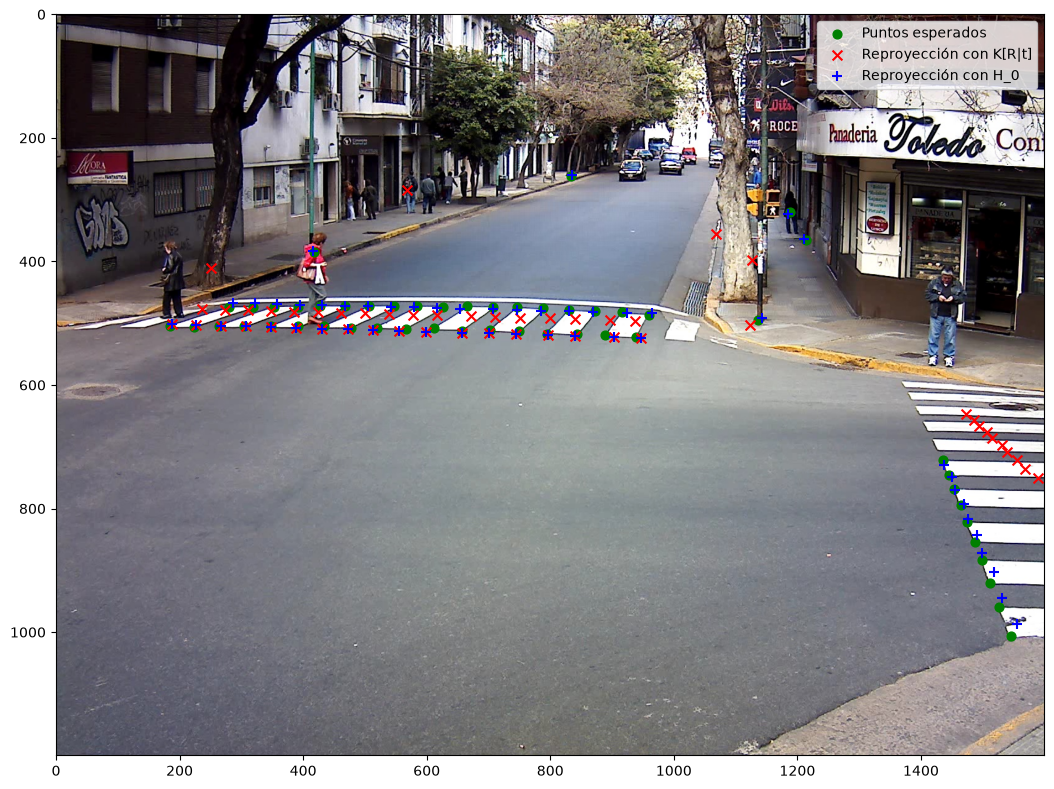

In [17]:
# Armamos la matriz de proyección para reproyectar los 51 puntos
Rt_0 = np.hstack((R_0, t_0.reshape((3, 1))))
M_0 = alc.mult_mat(K, Rt_0)

N_puntos = world_pts_51_UVW.shape[0]
u_repro_pose = np.zeros(N_puntos)
v_repro_pose = np.zeros(N_puntos)
u_repro_H = np.zeros(N_puntos)
v_repro_H = np.zeros(N_puntos)

for i in range(N_puntos):
    U, V, W = world_pts_51_UVW[i]

    # Reproyección usando la pose calculada: λ [u, v, 1]^T = M_0 [U, V, W, 1]^T
    punto_3d_hom = np.array([[U], [V], [W], [1]])
    proy_pose = alc.mult_mat(M_0, punto_3d_hom)
    u_repro_pose[i] = proy_pose[0, 0] / proy_pose[2, 0]
    v_repro_pose[i] = proy_pose[1, 0] / proy_pose[2, 0]

    # Reproyección usando la homografía H_0: λ [u, v, 1]^T = H_0 [U, V, 1]^T
    punto_2d_hom = np.array([[U], [V], [1]])
    proy_H = alc.mult_mat(H_0, punto_2d_hom)
    u_repro_H[i] = proy_H[0, 0] / proy_H[2, 0]
    v_repro_H[i] = proy_H[1, 0] / proy_H[2, 0]

# Comparamos los errores de reproyección, en píxeles.
errores_pose_cuadrados = (
    (u_repro_pose - img_pts_51[:, 0])**2
    + (v_repro_pose - img_pts_51[:, 1])**2
)
errores_H_cuadrados = (
    (u_repro_H - img_pts_51[:, 0])**2
    + (v_repro_H - img_pts_51[:, 1])**2
)

rms_pose_51 = np.sqrt(np.mean(errores_pose_cuadrados))
rms_H_51 = np.sqrt(np.mean(errores_H_cuadrados))
print(f"RMS con la pose K[R|t]: {rms_pose_51:.4f} px")
print(f"RMS con la homografía H_0: {rms_H_51:.4f} px")

# Graficamos los puntos originales y reproyectados sobre img_10_18_47_351.jpg
img_salguero_0 = mpimg.imread(os.path.join("salguero", "img_10_18_47_351.jpg"))

plt.figure(figsize=(12, 8))
plt.imshow(img_salguero_0)
plt.scatter(img_pts_51[:, 0], img_pts_51[:, 1], color="green", s=40, label="Puntos esperados")
plt.scatter(u_repro_pose, v_repro_pose, color="red", marker="x", s=50, label="Reproyección con K[R|t]")
plt.scatter(u_repro_H, v_repro_H, color="blue", marker="+", s=50, label="Reproyección con H_0")
plt.legend()
plt.tight_layout()
plt.show()

La reproyección con la pose $K[R|t]$ tiene un RMS de $92{,}9425$ píxeles, frente a $8{,}0922$ píxeles con la homografía $H_0$.

Aunque $R$ cumple la condición de ortogonalidad, el error de reproyección muestra que la pose obtenida no ajusta bien los puntos observados. Por ello, no la consideramos validada ya que su estimación depende de la calibración aproximada del inciso a).

En el inciso c) utilizamos directamente $H_0^{-1}$ para recuperar posiciones sobre el piso, por lo que ese cálculo no depende de la pose ni de $K$.


c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

Para cada agente tomamos el punto de contacto con el piso. Como los puntos de contacto pertenecen al plano de la calle ($W = 0$), llevamos cada punto de la imagen $(u, v)$ al plano de la calle calculando la inversa de $H_0$.

$$\lambda \begin{bmatrix} U \\ V \\ 1 \end{bmatrix} = H_0^{-1} \begin{bmatrix} u \\ v \\ 1 \end{bmatrix}$$

Finalmente dividimos por la tercera componente para obtener $(U, V)$ en metros.

Utilizamos posiciones de una selección de fotogramas: 11 para el taxi y 12 para la camioneta y la peatona. Para estimar cada velocidad usamos una muestra a cada lado en los vehículos y cuatro en la peatona. En los extremos de cada trayectoria usamos las posiciones disponibles. La elección de cuatro muestras para la peatona produce estimaciones sobre intervalos de tiempo más amplios.

Como las posiciones están en metros y los tiempos en segundos, el cociente $\|p_b-p_a\|_2/(t_b-t_a)$ queda expresado en metros por segundo. Multiplicamos por $3{,}6$ para presentar las velocidades en kilómetros por hora. En el gráfico, el tiempo se expresa en segundos transcurridos desde la primera captura.


Taxi: módulo de la velocidad media = 47.9675 km/h
Camioneta: módulo de la velocidad media = 48.5839 km/h
Señora: módulo de la velocidad media = 4.8534 km/h


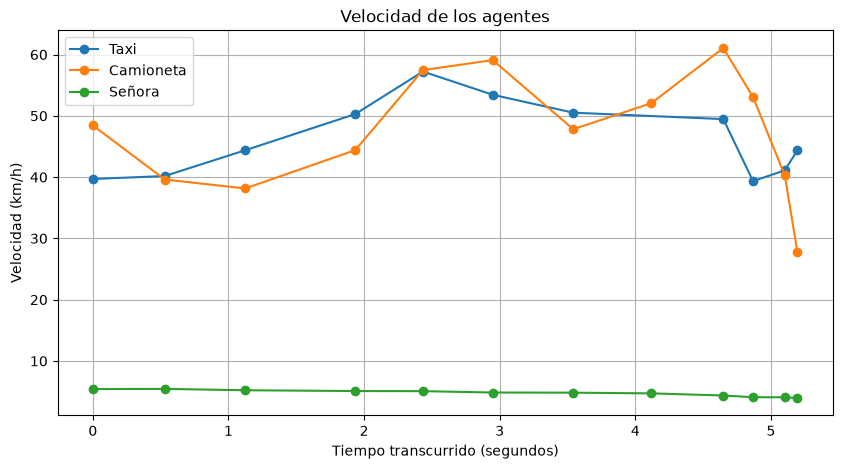

In [18]:
# Tiempo de cada captura
archivos_frames = sorted([
    a for a in os.listdir("salguero")
    if a.startswith("img_10_18_") and a.endswith(".jpg")
])
tiempos = []
for archivo in archivos_frames:
    _, horas, minutos, segundos, milisegundos = archivo[:-4].split("_")
    tiempo = (
        int(horas) * 3600
        + int(minutos) * 60
        + int(segundos)
        + int(milisegundos) / 1000.0
    )
    tiempos.append(tiempo)

tiempos = np.array(tiempos)

H0_inv = alc.inversa(H_0)

def pixel_a_mundo(u, v):
    """Lleva un punto de la imagen al plano del piso mediante H0_inv.

    Parámetros:
        u, v: coordenadas en píxeles de un punto situado sobre el piso.
    Retorna:
        Un vector con las coordenadas (U, V) en metros, suponiendo W=0.
    """
    q = alc.mult_mat(H0_inv, np.array([[u], [v], [1.0]]))[:, 0]
    return q[:2] / q[2]

# Puntos de contacto con el piso de los agentes
taxi_px = {0: (934, 270), 5: (918, 276), 10: (900, 284), 15: (866, 300), 20: (823, 315),
           25: (782, 337), 30: (735, 366), 40: (520, 474), 42: (460, 502),
           44: (396, 540), 45: (369, 560)}
camioneta_px = {0: (994, 261), 5: (991, 267), 10: (988, 272), 15: (980, 283), 20: (966, 292),
                25: (949, 309), 30: (930, 329), 35: (902, 351), 40: (854, 391),
                42: (832, 414), 44: (809, 436), 45: (802, 442)}
mujer_px = {0: (418, 492), 5: (492, 492), 10: (549, 492), 15: (642, 492), 20: (717, 492),
            25: (782, 492), 30: (837, 492), 35: (893, 492), 40: (952, 492),
            42: (968, 492), 44: (983, 492), 45: (989, 492)}

def secuenciaTrayecto(px):
    """Ordena las muestras y recupera sus posiciones sobre el piso.

    Parámetros:
        px: diccionario con índices de fotograma y sus píxeles (u, v).
    Retorna:
        idx: índices de fotograma ordenados.
        t: instantes de captura en segundos.
        pos: posiciones (U, V) sobre el piso, en metros.
    """
    idx = sorted(px)
    pos = np.array([pixel_a_mundo(*px[k]) for k in idx])
    return np.array(idx), tiempos[idx], pos

def velocidadesTrayecto(t, pos, paso_muestras=1):
    """Estima el módulo de la velocidad en cada muestra.

    Parámetros:
        t: instantes de captura en segundos, ordenados.
        pos: posiciones (U, V) en metros, correspondientes a esos instantes.
        paso_muestras: cantidad de muestras hacia cada lado que se utilizan.
    Retorna:
        Un vector de velocidades estimadas en km/h. En los extremos se
        utiliza el intervalo disponible.
    """
    velocidad = np.zeros(len(t))
    for i in range(len(t)):
        a, b = max(i - paso_muestras, 0), min(i + paso_muestras, len(t) - 1)
        velocidad[i] = alc.norma(pos[b] - pos[a], 2) / (t[b] - t[a]) * 3.6
    return velocidad

resultados = {}
for nombre, px, paso_muestras in [("Taxi", taxi_px, 1), ("Camioneta", camioneta_px, 1), ("Señora", mujer_px, 4)]:
    idx, t, pos = secuenciaTrayecto(px)
    resultados[nombre] = (t, velocidadesTrayecto(t, pos, paso_muestras))
    dist_total = alc.norma(pos[-1] - pos[0], 2)
    media = dist_total / (t[-1] - t[0]) * 3.6
    print(f"{nombre}: módulo de la velocidad media = {media:.4f} km/h")

# Gráfico de velocidades en el tiempo
plt.figure(figsize=(10, 5))
for nombre, (t, velocidad) in resultados.items():
    plt.plot(t - tiempos[0], velocidad, "o-", label=nombre)
plt.xlabel("Tiempo transcurrido (segundos)")
plt.ylabel("Velocidad (km/h)")
plt.title("Velocidad de los agentes")
plt.grid()
plt.legend()
plt.show()

Durante los aproximadamente $5{,}195$ segundos observados, los módulos de las velocidades medias estimadas son $47{,}9675$ km/h para el taxi, $48{,}5839$ km/h para la camioneta y $4{,}8534$ km/h para la peatona.

Estos valores se calculan entre la primera y la última posición de cada agente. Las curvas muestran estimaciones sobre intervalos locales de la trayectoria, con el intervalo más amplio elegido para la peatona. La precisión de los resultados depende de las posiciones seleccionadas y de la homografía utilizada.


### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

#### Puntos elegidos - inciso a del enunciado

Usamos los cinco puntos de `heli/object_points.csv`: el centro $M_0$ y las cuatro esquinas exteriores de la H. Sus coordenadas están en metros. $U$ crece hacia la derecha de la H, $V$ hacia su parte superior y $W=0$. El punto blanco identifica la esquina superior izquierda de la mira, aunque en la fotografía aparezca abajo a la izquierda.

Leímos visualmente sus píxeles sobre la fotografía ampliada y los guardamos en `heli/coordenadas_h_manual.csv`. La columna `indice` corresponde a la fila del archivo de puntos del objeto, empezando en cero. Las lecturas son aproximadas en píxeles, el centro se estima en el centro de la barra que une ambos lados de la H.

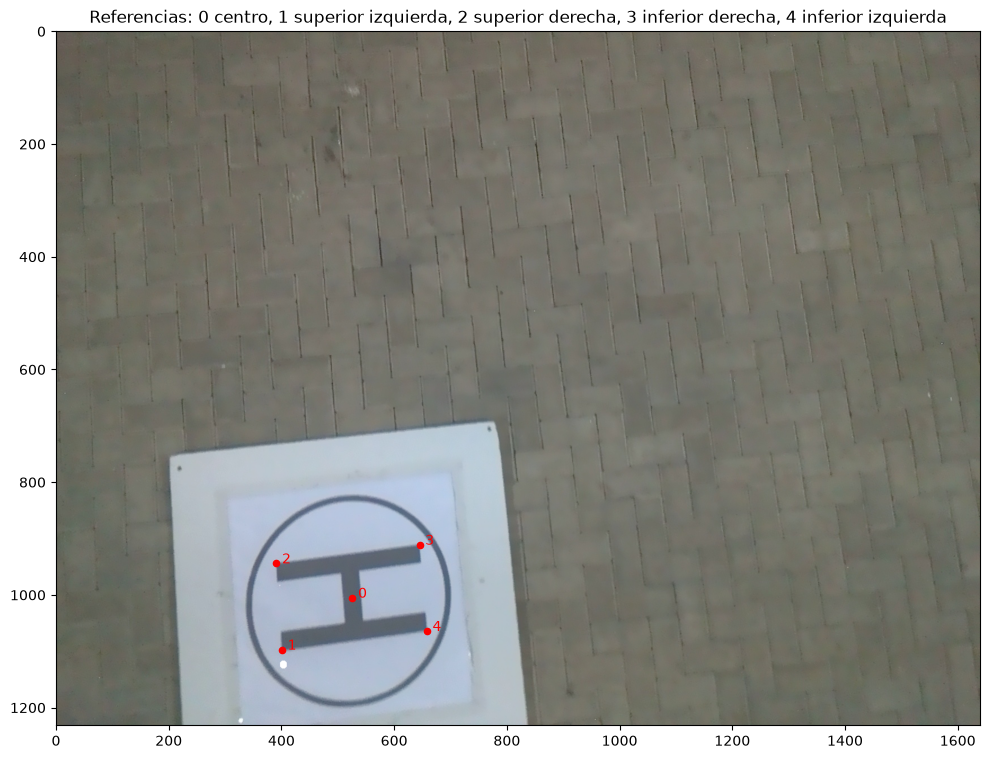

In [19]:

K_heli = np.loadtxt('heli/K.csv', delimiter=';')
obj_heli = np.loadtxt('heli/object_points.csv', delimiter=';', skiprows=1, usecols=(1, 2, 3))
mediciones_heli = np.loadtxt('heli/coordenadas_h_manual.csv', delimiter=',', skiprows=1)
img_heli = np.zeros((obj_heli.shape[0], 2))
for indice, u, v in mediciones_heli:
    img_heli[int(indice)] = [u, v]

foto_heli = mpimg.imread('heli/row_00248.png')
plt.figure(figsize=(10, 8))
plt.imshow(foto_heli)
plt.scatter(img_heli[:, 0], img_heli[:, 1], color='red', s=20)
for indice in range(img_heli.shape[0]):
    plt.text(img_heli[indice, 0] + 10, img_heli[indice, 1], str(indice), color='red')
plt.title('Referencias: 0 centro, 1 superior izquierda, 2 superior derecha, 3 inferior derecha, 4 inferior izquierda')
plt.tight_layout()
plt.show()

#### Implementación de POSIT - incisos b a e del enunciado

Las funciones están en `alc.py`. `calculoLambdaMu` obtiene los dos pares $(\lambda,\mu)$ que completan las soluciones coplanares. `calcularSalidaPOSIT` recupera una pose candidata y `evaluarPose` cuenta los puntos con profundidad positiva y calcula su RMS de reproyección.

`aplicarPOSIT` toma el primer punto como referencia y forma $A$ con los vectores desde él a los demás. Como los puntos pertenecen a un mismo plano y no están todos sobre una misma recta, $A$ tiene rango 2 y $A^TA$ no es invertible.

Usamos la normal unitaria $n$ del plano para calcular
$$A^+=(A^TA+nn^T)^{-1}A^T.$$

El término $nn^T$ completa la dirección normal, en la que $A^TA$ es nula, y permite invertir la matriz resultante. Como $A^Tb$ es perpendicular a $n$, obtenemos la solución de mínimos cuadrados de norma mínima.

Para contemplar las distintas focales de $K$, transformamos los píxeles mediante $K^{-1}$ a una cámara virtual con una única focal $f=K_{11}$.

Inicializamos $\epsilon_i=0$ y, en cada iteración:

1. Resolvemos los dos sistemas lineales POS.
2. Obtenemos las dos poses candidatas.
3. Descartamos las que no dejan todos los puntos delante de la cámara y elegimos la de menor RMS.
4. Actualizamos $\epsilon_i=a_i^Tk/Z_0$.

Nos detenemos al alcanzar `MaxIt` o cuando la reducción del RMS es menor que `atol`. Devolvemos la mejor pose visitada.

La convención de salida es $p_{\mathrm{cámara}}=Rp_{\mathrm{objeto}}+t$. La posición de la cámara en el sistema de la H es $C=-R^Tt$.

R =
[[-0.0920 -0.9430  0.3200]
 [-0.9924  0.0604 -0.1073]
 [ 0.0819 -0.3274 -0.9413]]
t (m) = [-0.6854  0.9016  4.4203]
Posición de la cámara respecto de la H, C (m) = [0.4698 0.7465 4.4770]
Puntos delante de la cámara: 5 de 5
RMS de reproyección (píxeles): 2.2396


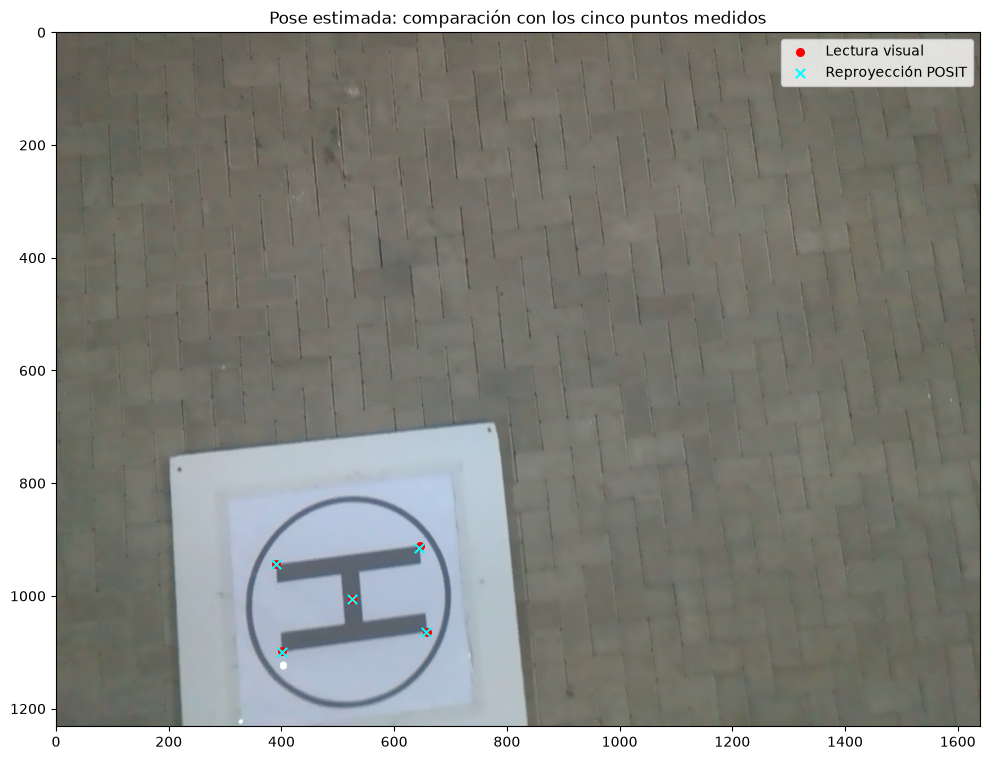

In [20]:
R_heli, t_heli = alc.aplicarPOSIT(obj_heli, img_heli, K_heli, MaxIt=1000, atol=1e-8)
validas_heli, rms_heli = alc.evaluarPose(R_heli, t_heli, obj_heli, img_heli, K_heli)
C_heli = -alc.mult_mat_vector(R_heli.T, t_heli)

print('R =')
print(R_heli)
print('t (m) =', t_heli)
print('Posición de la cámara respecto de la H, C (m) =', C_heli)
print('Puntos delante de la cámara:', validas_heli, 'de', obj_heli.shape[0])
print(f'RMS de reproyección (píxeles): {rms_heli:.4f}')

reproyectados_heli = np.zeros(img_heli.shape)
for indice in range(obj_heli.shape[0]):
    punto_camara = alc.mult_mat_vector(R_heli, obj_heli[indice]) + t_heli
    homogeneo = alc.mult_mat_vector(K_heli, punto_camara)
    reproyectados_heli[indice] = homogeneo[:2] / homogeneo[2]

plt.figure(figsize=(10, 8))
plt.imshow(foto_heli)
plt.scatter(img_heli[:, 0], img_heli[:, 1], color='red', s=30, label='Lectura visual')
plt.scatter(reproyectados_heli[:, 0], reproyectados_heli[:, 1], color='cyan', marker='x', s=45, label='Reproyección POSIT')
plt.title('Pose estimada: comparación con los cinco puntos medidos')
plt.legend()
plt.tight_layout()
plt.show()

Los cinco puntos quedan delante de la cámara. El RMS de reproyección es aproximadamente $2{,}24$ píxeles y resume la diferencia entre los puntos observados y sus proyecciones con la pose estimada.

La posición de la cámara en el sistema de la H es $C\approx(0{,}470,\,0{,}747,\,4{,}477)$ m. Su tercera coordenada representa la altura estimada sobre el plano de la H, aproximadamente $4{,}48$ m. Estos resultados se obtuvieron con las correspondencias leídas visualmente.


b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

#### Pose objetivo - inciso f del enunciado

Para quedar sobre el centro de la H y mirar perpendicularmente hacia el plano, la cámara debe estar en $C_{\mathrm{objetivo}}=(0,0,h)$, con $h>0$. Para que la H se vea derecha, con su esquina marcada arriba a la izquierda, elegimos
$$R_{\mathrm{objetivo}}=\begin{bmatrix}1&0&0\\0&-1&0\\0&0&-1\end{bmatrix},\qquad t_{\mathrm{objetivo}}=-R_{\mathrm{objetivo}}C_{\mathrm{objetivo}}=(0,0,h)^T.$$
Así, $+U$ se ve hacia la derecha, $+V$ hacia arriba de la imagen y el eje óptico apunta hacia $-W$.

El enunciado no fija una altura, por lo que hay una familia de soluciones. Como ejemplo numérico conservamos la altura estimada en la foto: $h=C_{\mathrm{heli},3}\simeq4{,}477$ m.

In [21]:
altura_objetivo = C_heli[2]
C_objetivo = np.array([0.0, 0.0, altura_objetivo])
R_objetivo = np.array([[1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, -1.0]])
t_objetivo = -alc.mult_mat_vector(R_objetivo, C_objetivo)

print('R objetivo =')
print(R_objetivo)
print('t objetivo (m) =', t_objetivo)
print('C objetivo (m) =', C_objetivo)
print('Dirección del eje óptico en el sistema de la H =', R_objetivo[2])

R objetivo =
[[ 1.0000  0.0000  0.0000]
 [ 0.0000 -1.0000  0.0000]
 [ 0.0000  0.0000 -1.0000]]
t objetivo (m) = [-0.0000 -0.0000  4.4770]
C objetivo (m) = [0.0000 0.0000 4.4770]
Dirección del eje óptico en el sistema de la H = [ 0.0000  0.0000 -1.0000]


---